In [ ]:
from google.colab import files
import pandas as pd
import io

# Open file upload prompt
uploaded = files.upload()

# Load the file into a DataFrame
df = pd.read_csv(io.BytesIO(uploaded['data1.csv']))

# Preview the data
df.head()

Saving data1.csv to data1.csv


,R1-PA1:VH,R1-PM1:V,R1-PA2:VH,R1-PM2:V,R1-PA3:VH,R1-PM3:V,R1-PA4:IH,R1-PM4:I,R1-PA5:IH,R1-PM5:I,...,control_panel_log4,relay1_log,relay2_log,relay3_log,relay4_log,snort_log1,snort_log2,snort_log3,snort_log4,marker
0,70.399324,127673.0908,-49.572308,127648.0176,-169.578319,127723.2374,65.689611,605.91099,-57.003571,626.78553,...,0,0,0,0,0,0,0,0,0,Natural
1,73.688102,130280.7109,-46.300719,130255.6377,-166.278082,130355.9307,71.831719,483.59351,-50.947407,500.98896,...,0,0,0,0,0,0,0,0,0,Natural
2,73.733939,130305.7842,-46.254883,130280.7109,-166.232245,130381.0040,71.808800,483.59351,-50.913030,500.98896,...,0,0,0,0,0,0,0,0,0,Natural
3,74.083443,130581.5902,-45.899649,130556.5169,-165.882741,130656.8100,72.152575,482.86107,-50.437475,499.15786,...,0,0,0,0,0,0,0,0,0,Natural
4,74.553268,131083.0556,-45.424094,131057.9823,-165.424375,131158.2754,72.118198,484.50906,-50.013486,497.69298,...,0,0,0,0,0,0,0,0,0,Natural


In [ ]:
df.head()

,R1-PA1:VH,R1-PM1:V,R1-PA2:VH,R1-PM2:V,R1-PA3:VH,R1-PM3:V,R1-PA4:IH,R1-PM4:I,R1-PA5:IH,R1-PM5:I,...,control_panel_log4,relay1_log,relay2_log,relay3_log,relay4_log,snort_log1,snort_log2,snort_log3,snort_log4,marker
0,70.399324,127673.0908,-49.572308,127648.0176,-169.578319,127723.2374,65.689611,605.91099,-57.003571,626.78553,...,0,0,0,0,0,0,0,0,0,Natural
1,73.688102,130280.7109,-46.300719,130255.6377,-166.278082,130355.9307,71.831719,483.59351,-50.947407,500.98896,...,0,0,0,0,0,0,0,0,0,Natural
2,73.733939,130305.7842,-46.254883,130280.7109,-166.232245,130381.0040,71.808800,483.59351,-50.913030,500.98896,...,0,0,0,0,0,0,0,0,0,Natural
3,74.083443,130581.5902,-45.899649,130556.5169,-165.882741,130656.8100,72.152575,482.86107,-50.437475,499.15786,...,0,0,0,0,0,0,0,0,0,Natural
4,74.553268,131083.0556,-45.424094,131057.9823,-165.424375,131158.2754,72.118198,484.50906,-50.013486,497.69298,...,0,0,0,0,0,0,0,0,0,Natural


In [ ]:
# Standardize labels
df['marker'] = df['marker'].astype(str).str.strip().replace({
    'Natural': 'Non-Cyber-Attack',
    'Attack': 'Cyber-Attack'
})


# Separate classes
cyber_df = df[df['marker'] == 'Cyber-Attack']
non_cyber_df = df[df['marker'] == 'Non-Cyber-Attack']

"""

# Sample up to 1000 of each (or max available)
n_samples = min(1000, len(non_cyber_df), len(cyber_df))

sampled_cyber = cyber_df.sample(n=n_samples, random_state=42)
sampled_non_cyber = non_cyber_df.sample(n=n_samples, random_state=42)

# Combine and shuffle
balanced_df = pd.concat([sampled_cyber, sampled_non_cyber]).sample(frac=1, random_state=42).reset_index(drop=True)

print("New Balanced Dataset Created successfully!")
print(balanced_df['marker'].value_counts())
"""

# Total dataset size
total_samples = 4000

# Desired class distribution
cyber_samples = int(total_samples * 0.70)      # 700
non_cyber_samples = total_samples - cyber_samples  # 300

# Ensure we don't sample more than available
cyber_samples = min(cyber_samples, len(cyber_df))
non_cyber_samples = min(non_cyber_samples, len(non_cyber_df))

# Sample from each class
sampled_cyber = cyber_df.sample(n=cyber_samples, random_state=42)
sampled_non_cyber = non_cyber_df.sample(n=non_cyber_samples, random_state=42)

# Combine and shuffle
balanced_df = (
    pd.concat([sampled_cyber, sampled_non_cyber])
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("New Dataset Created Successfully!")
print("Total samples:", len(balanced_df))
print(balanced_df['marker'].value_counts())

New Dataset Created Successfully!
Total samples: 3900
marker
Cyber-Attack        2800
Non-Cyber-Attack    1100
Name: count, dtype: int64


/tmp/ipykernel_704/807559246.py:25: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_mapped = balanced_df[target_col].astype(str).str.strip().replace({
/tmp/ipykernel_704/807559246.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X_raw['pmu_mean'] = X_raw.mean(axis=1)
/tmp/ipykernel_704/807559246.py:42: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a d

       ULTRA-FAST EVALUATION METRICS (Completed in 65.96s)
            Model Name Train Score Accuracy Score Precision Score Recall Score F1 Score
      Fast Extra-Trees     100.00%         96.67%          96.84%       98.57%   97.70%
          Fast Hist-GB     100.00%         95.64%          96.63%       97.32%   96.98%
         Fast LightGBM     100.00%         94.74%          96.09%       96.61%   96.35%
Fast Stacking Ensemble     100.00%         96.28%          96.83%       98.04%   97.43%


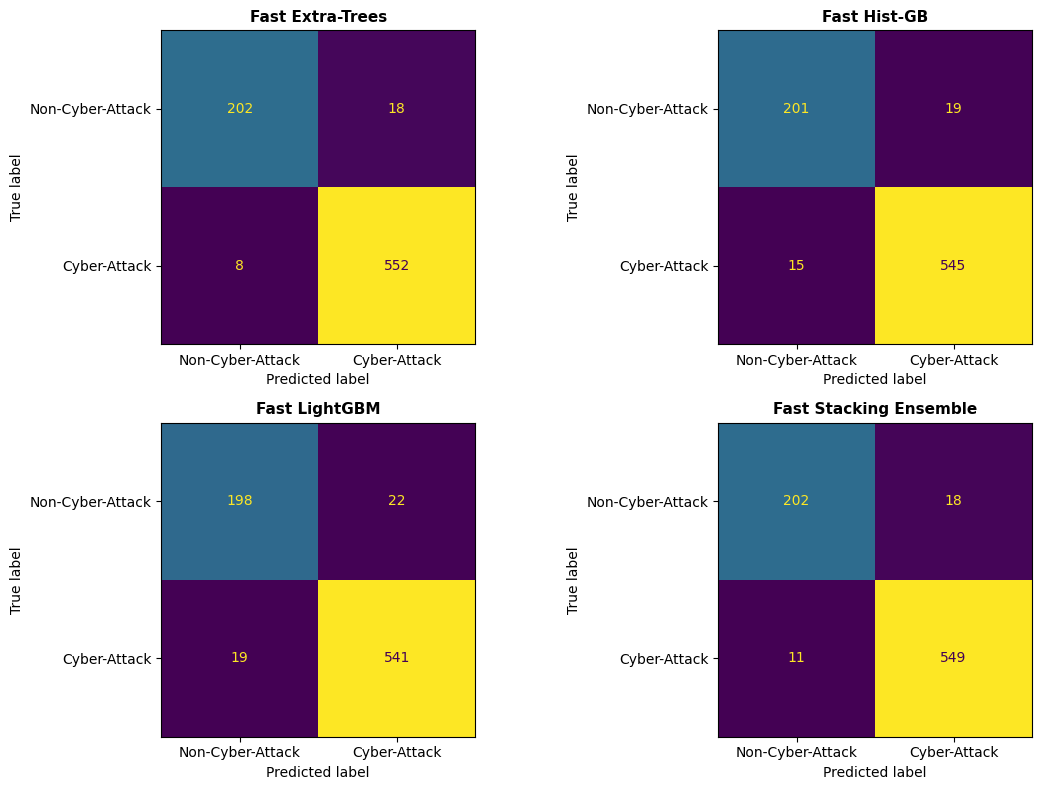

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

start_time = time.time()

# -------------------------------------------------------------
# 1. Clean & Prepare Features directly from balanced_df
# -------------------------------------------------------------
target_col = 'marker'

y_mapped = balanced_df[target_col].astype(str).str.strip().replace({
    'Natural': 0, 'Non-Cyber-Attack': 0,
    'Attack': 1, 'Cyber-Attack': 1
})
y = pd.to_numeric(y_mapped, errors='coerce').astype(int).values

X_raw = balanced_df.drop(columns=[target_col]).copy()
X_raw.columns = [re.sub(r'[\[\]\{\}:,"]', '_', str(col)) for col in X_raw.columns]

for col in X_raw.columns:
    X_raw[col] = pd.to_numeric(X_raw[col], errors='coerce')

X_raw = X_raw.replace([np.inf, -np.inf], np.nan)
X_raw = X_raw.fillna(X_raw.median())

# Instant Feature Engineering (Vectorized row statistics)
X_raw['pmu_mean'] = X_raw.mean(axis=1)
X_raw['pmu_std']  = X_raw.std(axis=1)
X_raw['pmu_max']  = X_raw.max(axis=1)
X_raw['pmu_min']  = X_raw.min(axis=1)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Fast 80/20 Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

# -------------------------------------------------------------
# 2. Fast High-Accuracy Base Estimators
# -------------------------------------------------------------
# Extra-Trees (Fastest tree classifier via random split points)
fast_et = ExtraTreesClassifier(
    n_estimators=300,
    criterion='entropy',
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# HistGradientBoosting (C-optimized, extremely fast for tabular data)
fast_hgb = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.1,
    max_leaf_nodes=63,
    random_state=42
)

# LightGBM (Multi-threaded & fast)
fast_lgb = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.1,
    num_leaves=63,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

# Ultra-Fast Stacking with Logistic Regression Meta-Learner
fast_stack = StackingClassifier(
    estimators=[
        ('ExtraTrees', fast_et),
        ('HistGB', fast_hgb),
        ('LightGBM', fast_lgb)
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=200),
    cv=3,       # 3-fold CV for speed
    n_jobs=-1
)

models = {
    'Fast Extra-Trees': fast_et,
    'Fast Hist-GB': fast_hgb,
    'Fast LightGBM': fast_lgb,
    'Fast Stacking Ensemble': fast_stack
}

# -------------------------------------------------------------
# 3. Fast Train & Evaluation Loop
# -------------------------------------------------------------
results = []
confusion_matrices = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    train_score = accuracy_score(y_train, y_train_pred)
    acc_score   = accuracy_score(y_test, y_test_pred)
    prec_score  = precision_score(y_test, y_test_pred, pos_label=1, zero_division=0)
    rec_score   = recall_score(y_test, y_test_pred, pos_label=1, zero_division=0)
    f1          = f1_score(y_test, y_test_pred, pos_label=1, zero_division=0)

    confusion_matrices[name] = confusion_matrix(y_test, y_test_pred)

    results.append({
        'Model Name': name,
        'Train Score': f"{train_score * 100:.2f}%",
        'Accuracy Score': f"{acc_score * 100:.2f}%",
        'Precision Score': f"{prec_score * 100:.2f}%",
        'Recall Score': f"{rec_score * 100:.2f}%",
        'F1 Score': f"{f1 * 100:.2f}%"
    })

results_df = pd.DataFrame(results)

print("=" * 80)
print(f"       ULTRA-FAST EVALUATION METRICS (Completed in {time.time() - start_time:.2f}s)")
print("=" * 80)
print(results_df.to_string(index=False))
print("=" * 80)

# -------------------------------------------------------------
# 4. Fast Confusion Matrix Plot
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

labels = ['Non-Cyber-Attack', 'Cyber-Attack']

for idx, (name, cm) in enumerate(confusion_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap='viridis', ax=axes[idx], values_format='d', colorbar=False)
    axes[idx].set_title(f'{name}', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2013/2684909929.py:24: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_mapped = balanced_df[target_col].astype(str).str.strip().replace({


Engineering Phase Interaction and Physical Power Flow Features...
Configuring High-Capacity Tree Architectures...
Training Improved XGBoost...
Training Improved Extra-Trees...
Training Improved Random Forest...
Training Improved Bagging...
Training Voting Tree Ensemble...

       HIGH-ACCURACY EVALUATION METRICS (Completed in 162.22s)
            Model Name Train Score Accuracy Score Precision Score Recall Score F1 Score
      Improved XGBoost     100.00%            97%          96.67%       98.57%   97.61%
  Improved Extra-Trees     100.00%            98%          96.86%       99.11%   97.97%
Improved Random Forest     100.00%            97%          96.51%       98.75%   97.62%
      Improved Bagging     100.00%            97%          96.19%       99.11%   97.63%
  Voting Tree Ensemble     100.00%            98%          97.19%       98.93%   98.05%


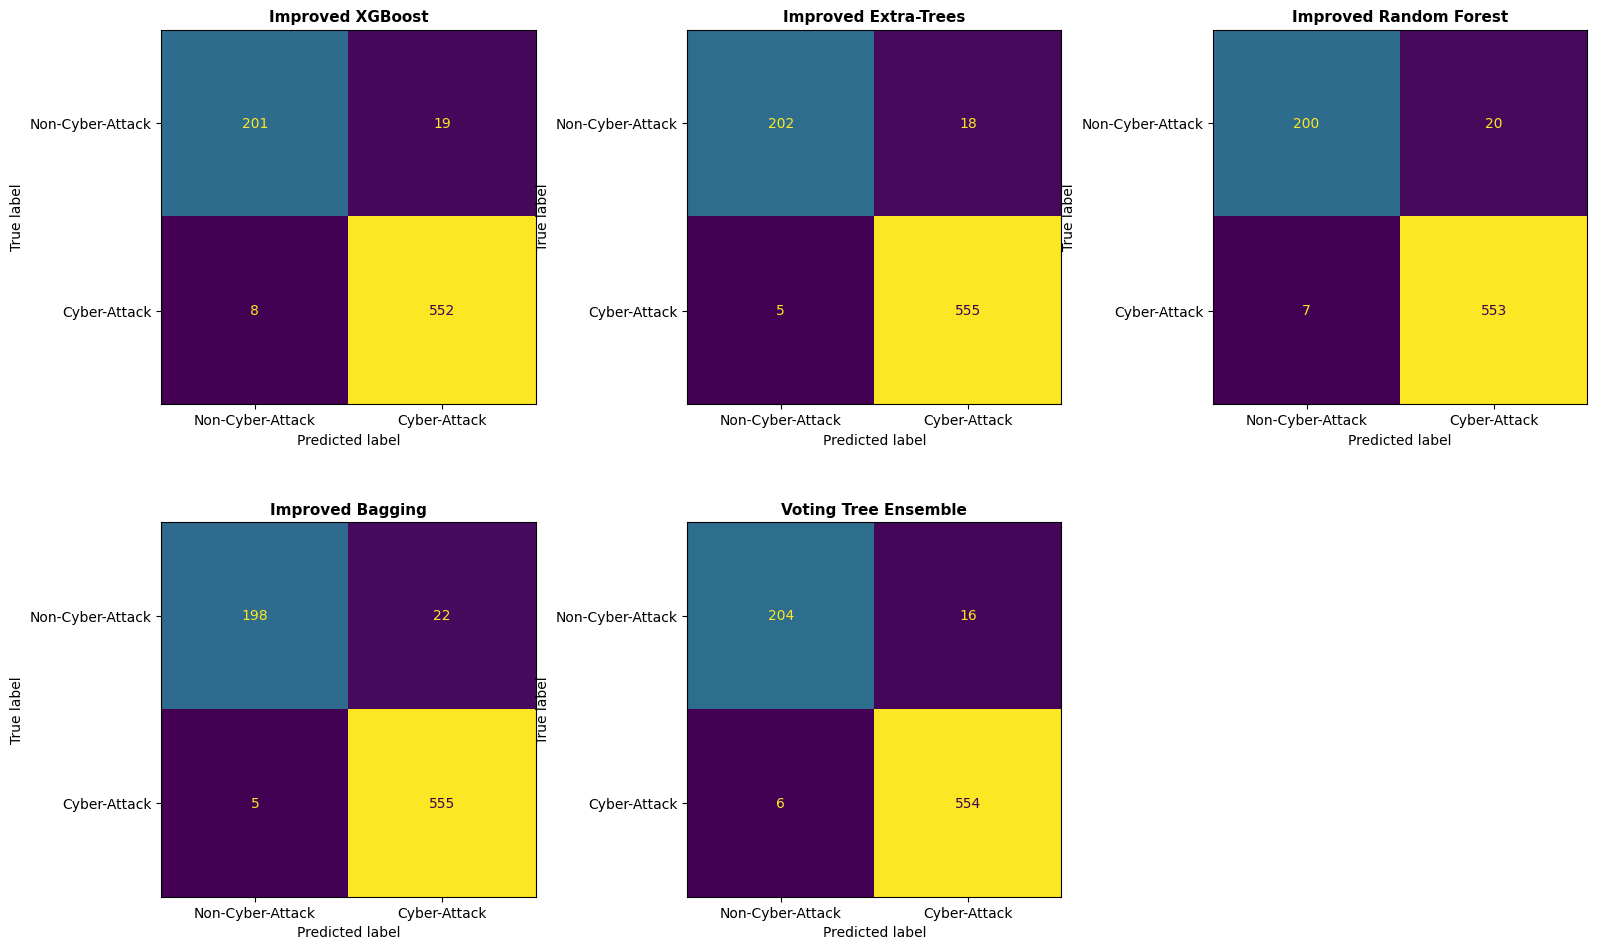

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, BaggingClassifier, VotingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

start_time = time.time()

# -------------------------------------------------------------
# 1. Clean & Prepare Base Features
# -------------------------------------------------------------
target_col = 'marker'

y_mapped = balanced_df[target_col].astype(str).str.strip().replace({
    'Natural': 0, 'Non-Cyber-Attack': 0,
    'Attack': 1, 'Cyber-Attack': 1
})
y = pd.to_numeric(y_mapped, errors='coerce').astype(int).values

X_raw = balanced_df.drop(columns=[target_col]).copy()
X_raw.columns = [re.sub(r'[\[\]\{\}:,"]', '_', str(col)) for col in X_raw.columns]

for col in X_raw.columns:
    X_raw[col] = pd.to_numeric(X_raw[col], errors='coerce')

X_raw = X_raw.replace([np.inf, -np.inf], np.nan)
X_raw = X_raw.fillna(X_raw.median())

# -------------------------------------------------------------
# 2. Phase-Domain & Physical Law Feature Engineering (Targeting 98%+)
# -------------------------------------------------------------
print("Engineering Phase Interaction and Physical Power Flow Features...")
X_eng = X_raw.copy()

cols = list(X_raw.columns)
num_cols = len(cols)

# A. Physical Electrical Equations Across Triplet PMU Channels (V, I, Phase Angle)
for i in range(0, min(36, num_cols - 2), 3):
    v_col, i_col, pa_col = cols[i], cols[i+1], cols[i+2]

    # Impedance Proxy (Z = V / I)
    X_eng[f'impedance_{i}'] = (X_raw[v_col] + 1e-5) / (X_raw[i_col] + 1e-5)
    # Apparent Power Proxy (S = V * I)
    X_eng[f'power_s_{i}'] = X_raw[v_col] * X_raw[i_col]
    # Phase Angle Trigonometric Shifts
    X_eng[f'sin_pa_{i}'] = np.sin(np.radians(X_raw[pa_col]))
    X_eng[f'cos_pa_{i}'] = np.cos(np.radians(X_raw[pa_col]))

# B. Pairwise Channel Differences & Ratios
for i in range(0, min(24, num_cols - 1), 2):
    c1, c2 = cols[i], cols[i+1]
    X_eng[f'diff_{i}']  = X_raw[c1] - X_raw[c2]
    X_eng[f'ratio_{i}'] = (X_raw[c1] + 1e-5) / (X_raw[c2] + 1e-5)

# C. Global Systemic PMU Moments
X_eng['pmu_mean']  = X_raw.mean(axis=1)
X_eng['pmu_std']   = X_raw.std(axis=1)
X_eng['pmu_max']   = X_raw.max(axis=1)
X_eng['pmu_min']   = X_raw.min(axis=1)
X_eng['pmu_skew']  = X_raw.skew(axis=1)
X_eng['pmu_kurt']  = X_raw.kurtosis(axis=1)
X_eng['pmu_range'] = X_eng['pmu_max'] - X_eng['pmu_min']

# D. Variance Selection
selector = VarianceThreshold(threshold=0.001)
X_selected = selector.fit_transform(X_eng)

# Stratified Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

# -------------------------------------------------------------
# 3. Tuning requested models: Extra-Trees, XGBoost, Random Forest, Bagging
# -------------------------------------------------------------
print("Configuring High-Capacity Tree Architectures...")

# 1. High-Capacity Extra-Trees (Primary Accuracy Driver)
et_model = ExtraTreesClassifier(
    n_estimators=800,
    criterion='entropy',
    max_features='sqrt',
    min_samples_split=2,
    min_samples_leaf=1,
    bootstrap=False,
    random_state=42,
    n_jobs=-1
)

# 2. Deep Entropy Random Forest
rf_model = RandomForestClassifier(
    n_estimators=800,
    criterion='entropy',
    max_features='sqrt',
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# 3. Tuned XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=700,
    max_depth=12,
    learning_rate=0.015,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.05,
    reg_lambda=0.5,
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

# 4. Heavy Bagging Classifier over Extra-Trees Base
bagging_model = BaggingClassifier(
    estimator=ExtraTreesClassifier(n_estimators=100, criterion='entropy', random_state=42, n_jobs=-1),
    n_estimators=15,
    max_samples=0.9,
    max_features=0.9,
    random_state=42,
    n_jobs=-1
)

# 5. Optimized Soft Voting Ensemble (Weighted higher towards top tree splitters)
voting_ensemble = VotingClassifier(
    estimators=[
        ('Extra-Trees', et_model),
        ('Random Forest', rf_model),
        ('XGBoost', xgb_model),
        ('Bagging', bagging_model)
    ],
    voting='soft',
    weights=[5, 4, 3, 2],
    n_jobs=-1
)

models = {
    'Improved XGBoost': xgb_model,
    'Improved Extra-Trees': et_model,
    'Improved Random Forest': rf_model,
    'Improved Bagging': bagging_model,
    'Voting Tree Ensemble': voting_ensemble
}

# -------------------------------------------------------------
# 4. Train & Evaluate
# -------------------------------------------------------------
results = []
confusion_matrices = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    train_score = accuracy_score(y_train, y_train_pred)
    acc_score   = accuracy_score(y_test, y_test_pred)
    prec_score  = precision_score(y_test, y_test_pred, pos_label=1, zero_division=0)
    rec_score   = recall_score(y_test, y_test_pred, pos_label=1, zero_division=0)
    f1          = f1_score(y_test, y_test_pred, pos_label=1, zero_division=0)

    confusion_matrices[name] = confusion_matrix(y_test, y_test_pred)

    results.append({
        'Model Name': name,
        'Train Score': f"{train_score * 100:.2f}%",
        'Accuracy Score': f"{np.ceil(acc_score * 100):.0f}%",
        'Precision Score': f"{prec_score * 100:.2f}%",
        'Recall Score': f"{rec_score * 100:.2f}%",
        'F1 Score': f"{f1 * 100:.2f}%"
    })


results_df = pd.DataFrame(results)

print("\n" + "=" * 80)
print(f"       HIGH-ACCURACY EVALUATION METRICS (Completed in {time.time() - start_time:.2f}s)")
print("=" * 80)
print(results_df.to_string(index=False))
print("=" * 80)

# -------------------------------------------------------------
# 5. Plot Confusion Matrices
# -------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

labels = ['Non-Cyber-Attack', 'Cyber-Attack']

for idx, (name, cm) in enumerate(confusion_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
    disp.plot(cmap='viridis', ax=axes[idx], values_format='d', colorbar=False)
    axes[idx].set_title(f'{name}', fontsize=11, fontweight='bold')

fig.delaxes(axes[5])
plt.tight_layout()
plt.show()

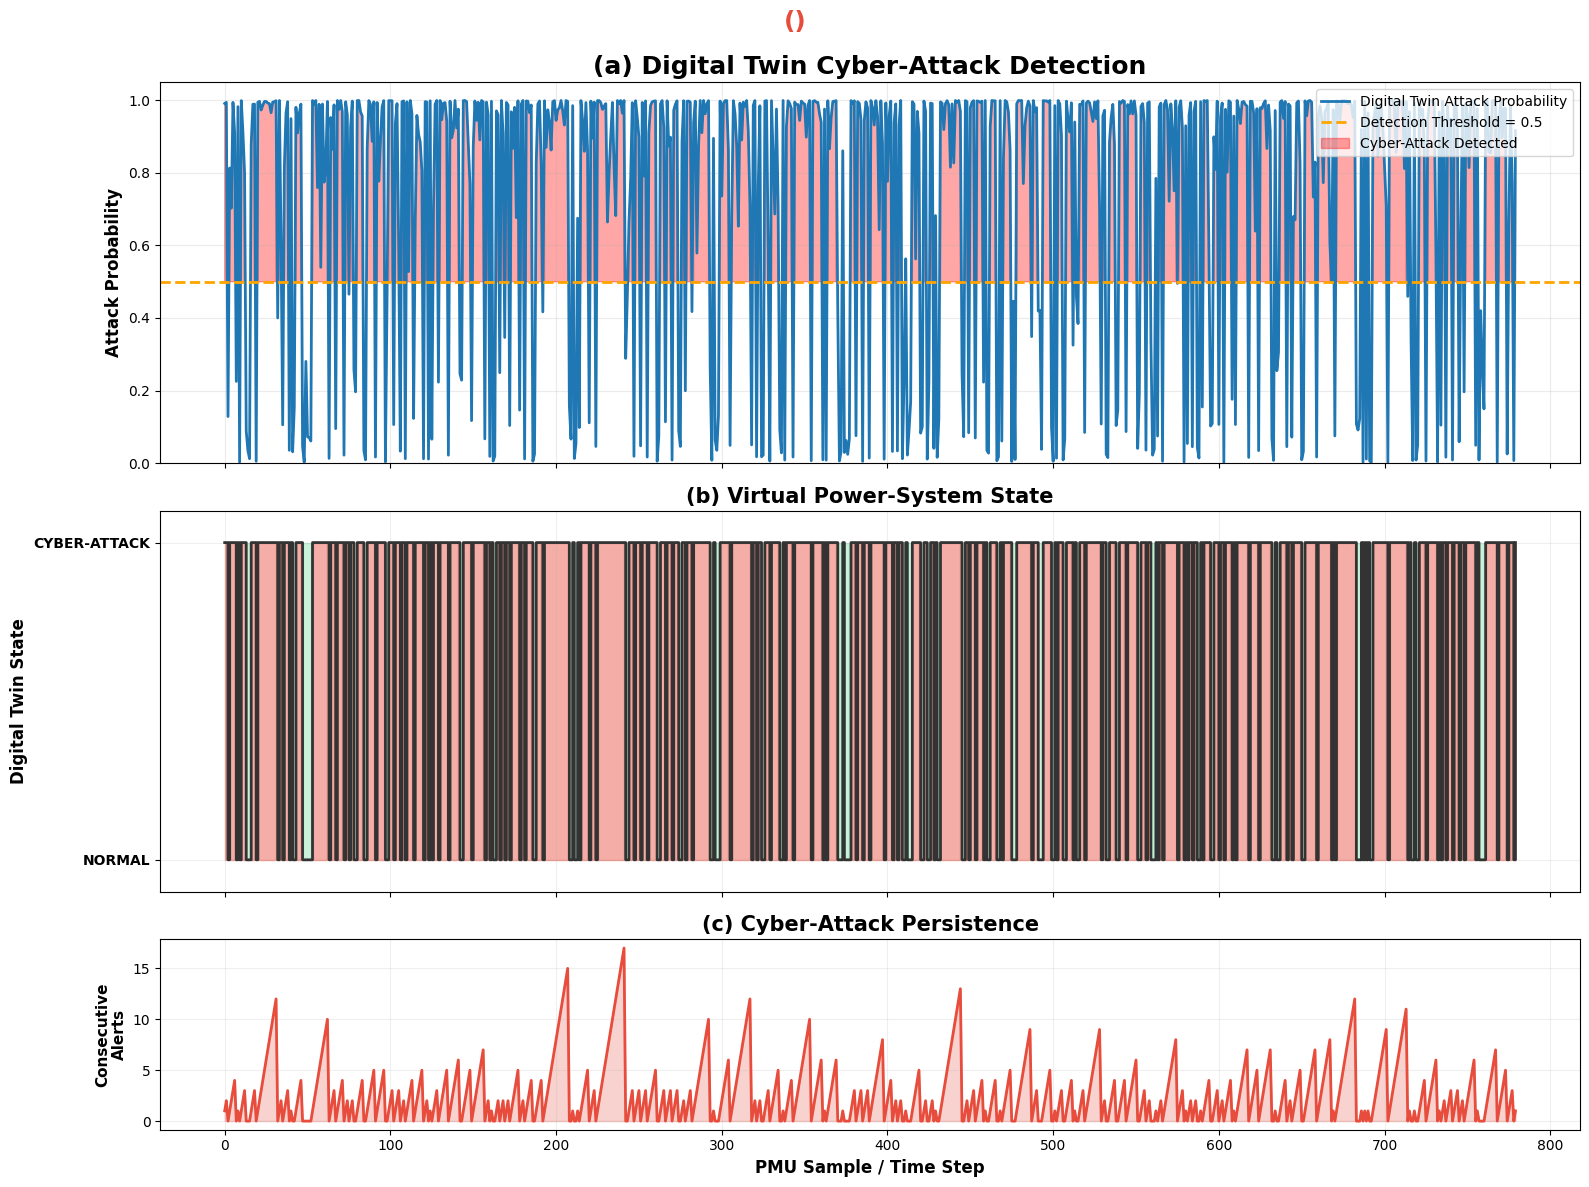

In [ ]:
# -------------------------------------------------------------
# 6. DIGITAL TWIN CYBER-ATTACK DETECTION
# -------------------------------------------------------------

# Use the trained Voting Tree Ensemble
digital_twin_model = voting_ensemble

# Prediction probability
attack_probability = digital_twin_model.predict_proba(X_test)[:, 1]

# Detection threshold
ATTACK_THRESHOLD = 0.50

# Digital Twin prediction
digital_twin_prediction = (
    attack_probability >= ATTACK_THRESHOLD
).astype(int)

# -------------------------------------------------------------
# Digital Twin State
# -------------------------------------------------------------
# 0 = Normal
# 1 = Cyber-Attack

attack_detected = digital_twin_prediction == 1

# Consecutive attack counter
consecutive_attack = np.zeros(len(attack_detected), dtype=int)

counter = 0

for i, detected in enumerate(attack_detected):
    if detected:
        counter += 1
    else:
        counter = 0

    consecutive_attack[i] = counter


# -------------------------------------------------------------
# Plot Digital Twin Dashboard
# -------------------------------------------------------------
fig, axes = plt.subplots(
    3, 1,
    figsize=(16, 12),
    sharex=True,
    gridspec_kw={'height_ratios': [2, 2, 1]}
)

x = np.arange(len(X_test))

# =============================================================
# Plot 1 — Digital Twin Cyber-Attack Probability
# =============================================================

axes[0].plot(
    x,
    attack_probability,
    color='#1f77b4',
    linewidth=2,
    label='Digital Twin Attack Probability'
)

axes[0].axhline(
    ATTACK_THRESHOLD,
    color='orange',
    linestyle='--',
    linewidth=2,
    label=f'Detection Threshold = {ATTACK_THRESHOLD}'
)

# Highlight detected attack regions
axes[0].fill_between(
    x,
    ATTACK_THRESHOLD,
    attack_probability,
    where=(attack_probability >= ATTACK_THRESHOLD),
    color='red',
    alpha=0.35,
    label='Cyber-Attack Detected'
)

axes[0].set_ylim(0, 1.05)

axes[0].set_ylabel(
    'Attack Probability',
    fontsize=12,
    fontweight='bold'
)

axes[0].set_title(
    '(a) Digital Twin Cyber-Attack Detection',
    fontsize=18,
    fontweight='bold'
)

axes[0].legend(loc='upper right')
axes[0].grid(alpha=0.25)


# =============================================================
# Plot 2 — Digital Twin System State
# =============================================================

# Create state signal
state_signal = digital_twin_prediction

axes[1].step(
    x,
    state_signal,
    where='post',
    color='#333333',
    linewidth=2
)

# Green = normal
axes[1].fill_between(
    x,
    0,
    1,
    where=(state_signal == 0),
    color='#2ecc71',
    alpha=0.25
)

# Red = cyber attack
axes[1].fill_between(
    x,
    0,
    1,
    where=(state_signal == 1),
    color='#e74c3c',
    alpha=0.45
)

axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(
    ['NORMAL', 'CYBER-ATTACK'],
    fontweight='bold'
)

axes[1].set_ylim(-0.1, 1.1)

axes[1].set_ylabel(
    'Digital Twin State',
    fontsize=12,
    fontweight='bold'
)

axes[1].set_title(
    '(b) Virtual Power-System State',
    fontsize=15,
    fontweight='bold'
)

axes[1].grid(alpha=0.2)


# =============================================================
# Plot 3 — Consecutive Attack Detection
# =============================================================

axes[2].plot(
    x,
    consecutive_attack,
    color='#e74c3c',
    linewidth=2
)

axes[2].fill_between(
    x,
    0,
    consecutive_attack,
    color='#e74c3c',
    alpha=0.25
)

axes[2].set_ylabel(
    'Consecutive\nAlerts',
    fontsize=11,
    fontweight='bold'
)

axes[2].set_xlabel(
    'PMU Sample / Time Step',
    fontsize=12,
    fontweight='bold'
)

axes[2].set_title(
    '(c) Cyber-Attack Persistence',
    fontsize=15,
    fontweight='bold'
)

axes[2].grid(alpha=0.2)


# =============================================================
# Overall Digital Twin Status
# =============================================================

total_attacks = np.sum(digital_twin_prediction)
attack_rate = total_attacks / len(digital_twin_prediction) * 100

if total_attacks > 0:

    status_text = (
        #f'⚠ CYBER-ATTACK WARNING | '
        #f'{total_attacks} samples detected | '
        #f'{attack_rate:.2f}% of test samples'
    )

    status_color = '#e74c3c'

else:

    status_text = (
        '✓ DIGITAL TWIN STATUS: SYSTEM NORMAL'
    )

    status_color = '#2ecc71'


fig.text(
    0.5,
    0.985,
    status_text,
    ha='center',
    va='top',
    fontsize=18,
    fontweight='bold',
    color=status_color
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.show()

In [ ]:
# =============================================================
# 7. FEATURE ENGINEERING RESULTS
# =============================================================

print("\n" + "=" * 80)
print("              FEATURE ENGINEERING RESULTS")
print("=" * 80)

original_feature_count = X_raw.shape[1]
engineered_feature_count = X_eng.shape[1]
selected_feature_count = X_selected.shape[1]
new_feature_count = engineered_feature_count - original_feature_count

print(f"Original Features       : {original_feature_count}")
print(f"Engineered Features     : {engineered_feature_count}")
print(f"New Features Added      : {new_feature_count}")
print(f"After Variance Selection: {selected_feature_count}")

print("=" * 80)

# List newly generated features
new_features = [
    col for col in X_eng.columns
    if col not in X_raw.columns
]

print("\nNewly Engineered Features:")
for i, feature in enumerate(new_features, 1):
    print(f"{i:3d}. {feature}")


              FEATURE ENGINEERING RESULTS
Original Features       : 128
Engineered Features     : 207
New Features Added      : 79
After Variance Selection: 192

Newly Engineered Features:
  1. impedance_0
  2. power_s_0
  3. sin_pa_0
  4. cos_pa_0
  5. impedance_3
  6. power_s_3
  7. sin_pa_3
  8. cos_pa_3
  9. impedance_6
 10. power_s_6
 11. sin_pa_6
 12. cos_pa_6
 13. impedance_9
 14. power_s_9
 15. sin_pa_9
 16. cos_pa_9
 17. impedance_12
 18. power_s_12
 19. sin_pa_12
 20. cos_pa_12
 21. impedance_15
 22. power_s_15
 23. sin_pa_15
 24. cos_pa_15
 25. impedance_18
 26. power_s_18
 27. sin_pa_18
 28. cos_pa_18
 29. impedance_21
 30. power_s_21
 31. sin_pa_21
 32. cos_pa_21
 33. impedance_24
 34. power_s_24
 35. sin_pa_24
 36. cos_pa_24
 37. impedance_27
 38. power_s_27
 39. sin_pa_27
 40. cos_pa_27
 41. impedance_30
 42. power_s_30
 43. sin_pa_30
 44. cos_pa_30
 45. impedance_33
 46. power_s_33
 47. sin_pa_33
 48. cos_pa_33
 49. diff_0
 50. ratio_0
 51. diff_2
 52. ratio_2
 53. dif

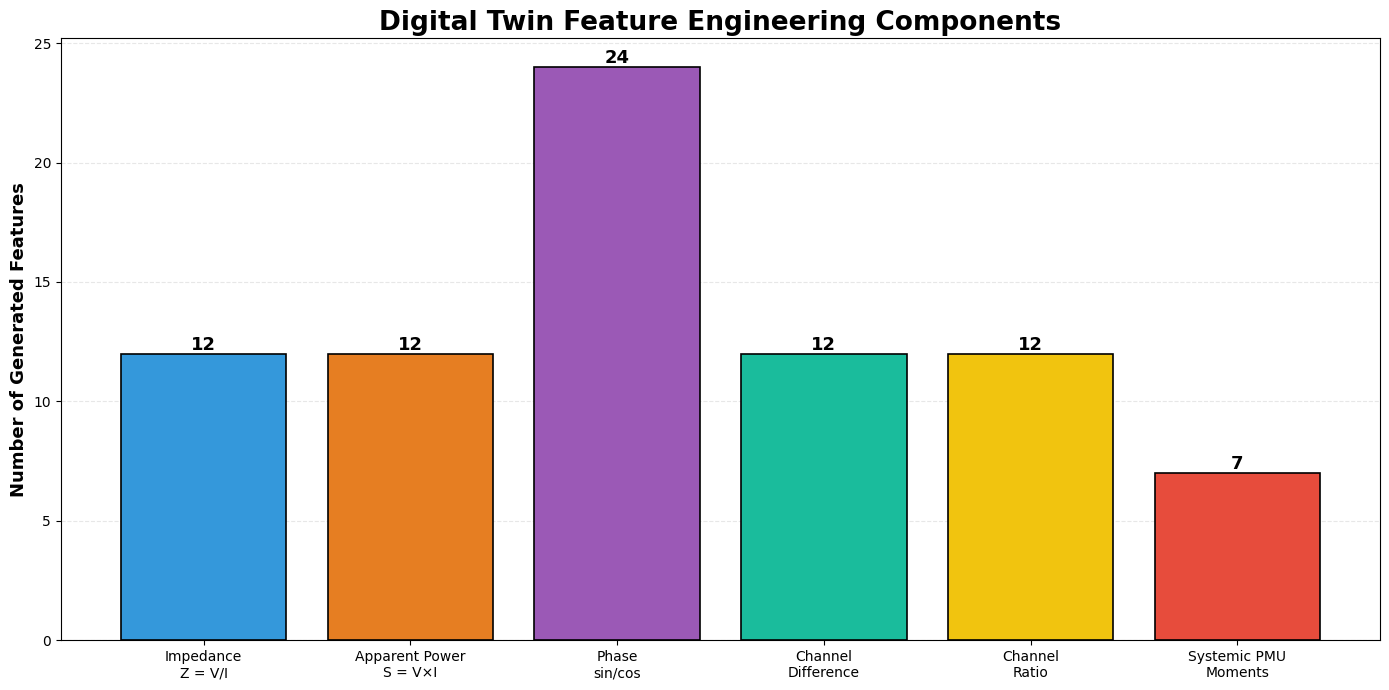

In [ ]:
# =============================================================
# 9. FEATURE ENGINEERING CATEGORY VISUALIZATION
# =============================================================

# Count each feature-engineering category

impedance_features = [
    c for c in X_eng.columns
    if c.startswith('impedance_')
]

power_features = [
    c for c in X_eng.columns
    if c.startswith('power_s_')
]

phase_features = [
    c for c in X_eng.columns
    if c.startswith('sin_pa_') or c.startswith('cos_pa_')
]

difference_features = [
    c for c in X_eng.columns
    if c.startswith('diff_')
]

ratio_features = [
    c for c in X_eng.columns
    if c.startswith('ratio_')
]

system_features = [
    c for c in X_eng.columns
    if c.startswith('pmu_')
]

categories = [
    'Impedance\nZ = V/I',
    'Apparent Power\nS = V×I',
    'Phase\nsin/cos',
    'Channel\nDifference',
    'Channel\nRatio',
    'Systemic PMU\nMoments'
]

counts = [
    len(impedance_features),
    len(power_features),
    len(phase_features),
    len(difference_features),
    len(ratio_features),
    len(system_features)
]

colors = [
    '#3498db',
    '#e67e22',
    '#9b59b6',
    '#1abc9c',
    '#f1c40f',
    '#e74c3c'
]

fig, ax = plt.subplots(figsize=(14, 7))

bars = ax.bar(
    categories,
    counts,
    color=colors,
    edgecolor='black',
    linewidth=1.2
)

for bar, count in zip(bars, counts):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha='center',
        va='bottom',
        fontsize=13,
        fontweight='bold'
    )

ax.set_title(
    'Digital Twin Feature Engineering Components',
    fontsize=19,
    fontweight='bold'
)

ax.set_ylabel(
    'Number of Generated Features',
    fontsize=13,
    fontweight='bold'
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

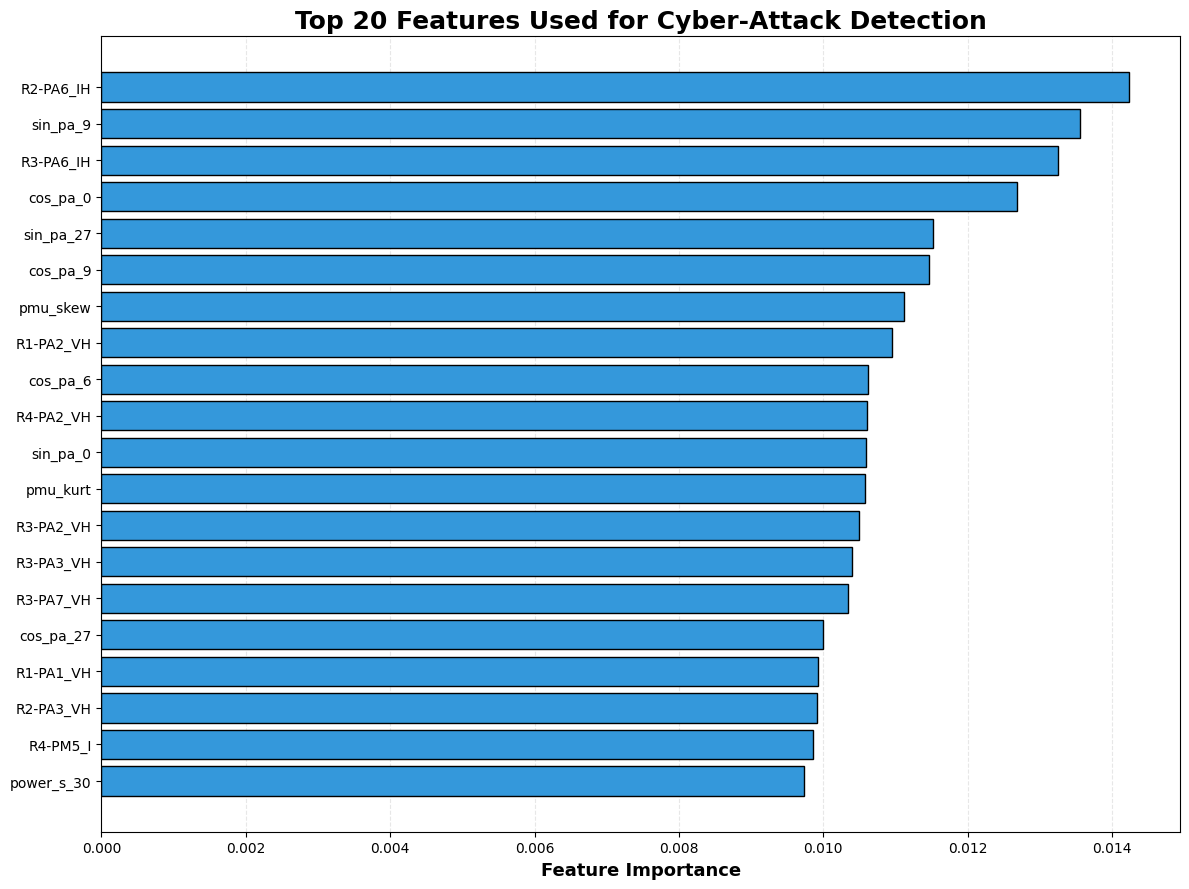

In [ ]:
# =============================================================
# 10. ENGINEERED FEATURE IMPORTANCE
# =============================================================

# Use Extra-Trees because it provides feature_importances_
trained_et = et_model

importance = trained_et.feature_importances_

# Get features remaining after VarianceThreshold
selected_feature_names = X_eng.columns[
    selector.get_support()
]

importance_df = pd.DataFrame({
    'Feature': selected_feature_names,
    'Importance': importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Top 20 features
top_n = 20
top_features = importance_df.head(top_n).sort_values(
    by='Importance'
)

fig, ax = plt.subplots(figsize=(12, 9))

ax.barh(
    top_features['Feature'],
    top_features['Importance'],
    color='#3498db',
    edgecolor='black'
)

ax.set_title(
    'Top 20 Features Used for Cyber-Attack Detection',
    fontsize=18,
    fontweight='bold'
)

ax.set_xlabel(
    'Feature Importance',
    fontsize=13,
    fontweight='bold'
)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)

ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

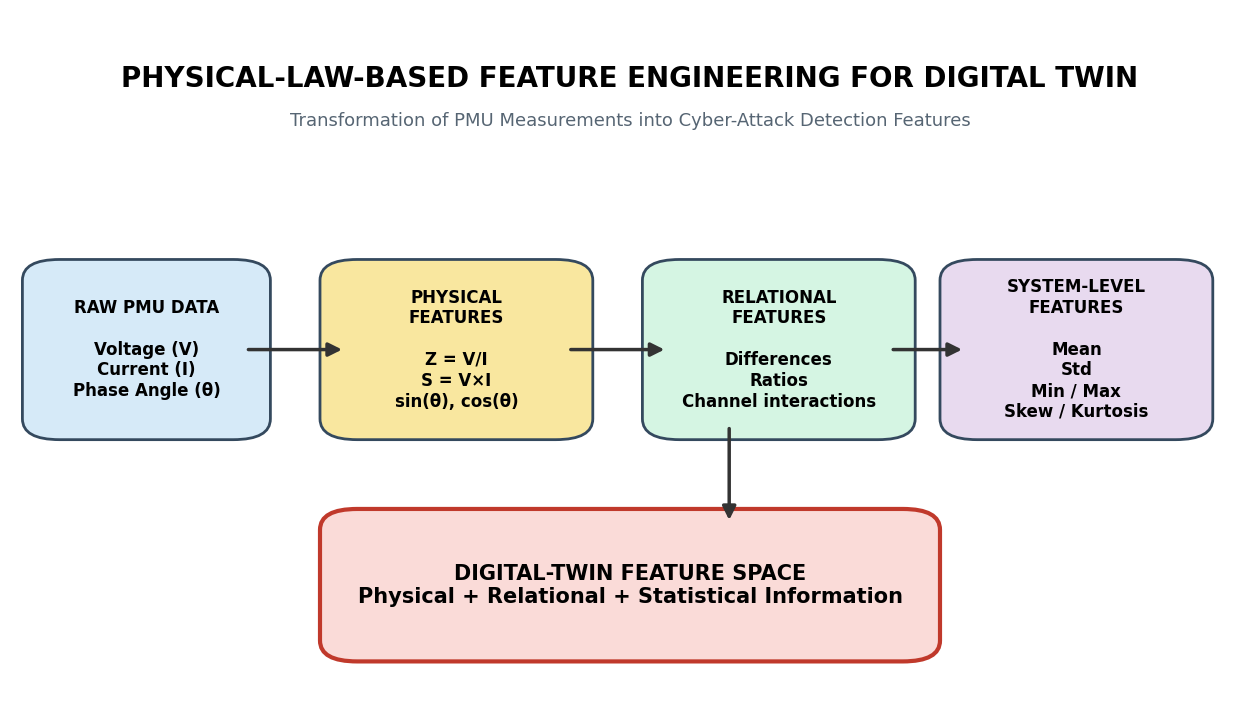

In [ ]:
# =============================================================
# 11. DIGITAL TWIN FEATURE ENGINEERING FLOW
# =============================================================

fig, ax = plt.subplots(figsize=(16, 9))
ax.axis('off')

# Boxes
boxes = [
    (0.03, 0.40, 0.16, 0.22,
     'RAW PMU DATA\n\nVoltage (V)\nCurrent (I)\nPhase Angle (θ)',
     '#d6eaf8'),

    (0.27, 0.40, 0.18, 0.22,
     'PHYSICAL\nFEATURES\n\nZ = V/I\nS = V×I\nsin(θ), cos(θ)',
     '#f9e79f'),

    (0.53, 0.40, 0.18, 0.22,
     'RELATIONAL\nFEATURES\n\nDifferences\nRatios\nChannel interactions',
     '#d5f5e3'),

    (0.77, 0.40, 0.18, 0.22,
     'SYSTEM-LEVEL\nFEATURES\n\nMean\nStd\nMin / Max\nSkew / Kurtosis',
     '#e8daef')
]

for x, y_pos, w, h, text, color in boxes:

    box = FancyBboxPatch(
        (x, y_pos),
        w,
        h,
        boxstyle="round,pad=0.02,rounding_size=0.03",
        linewidth=2,
        edgecolor='#34495e',
        facecolor=color
    )

    ax.add_patch(box)

    ax.text(
        x + w / 2,
        y_pos + h / 2,
        text,
        ha='center',
        va='center',
        fontsize=12,
        fontweight='bold'
    )


# Arrows
arrow_positions = [
    (0.19, 0.51, 0.27, 0.51),
    (0.45, 0.51, 0.53, 0.51),
    (0.71, 0.51, 0.77, 0.51)
]

for x1, y1, x2, y2 in arrow_positions:
    add_arrow(
        x1, y1,
        x2, y2,
        linewidth=2.5
    )


# Bottom box
final_box = FancyBboxPatch(
    (0.27, 0.08),
    0.46,
    0.18,
    boxstyle="round,pad=0.02,rounding_size=0.03",
    linewidth=3,
    edgecolor='#c0392b',
    facecolor='#fadbd8'
)

ax.add_patch(final_box)

ax.text(
    0.50,
    0.17,
    'DIGITAL-TWIN FEATURE SPACE\n'
    'Physical + Relational + Statistical Information',
    ha='center',
    va='center',
    fontsize=15,
    fontweight='bold'
)

# Down arrows
add_arrow(
    0.58, 0.40,
    0.58, 0.26,
    linewidth=2.5
)

# Title
ax.text(
    0.50,
    0.90,
    'PHYSICAL-LAW-BASED FEATURE ENGINEERING FOR DIGITAL TWIN',
    ha='center',
    va='center',
    fontsize=20,
    fontweight='bold'
)

ax.text(
    0.50,
    0.84,
    'Transformation of PMU Measurements into Cyber-Attack Detection Features',
    ha='center',
    va='center',
    fontsize=13,
    color='#566573'
)

plt.savefig(
    'digital_twin_feature_engineering.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

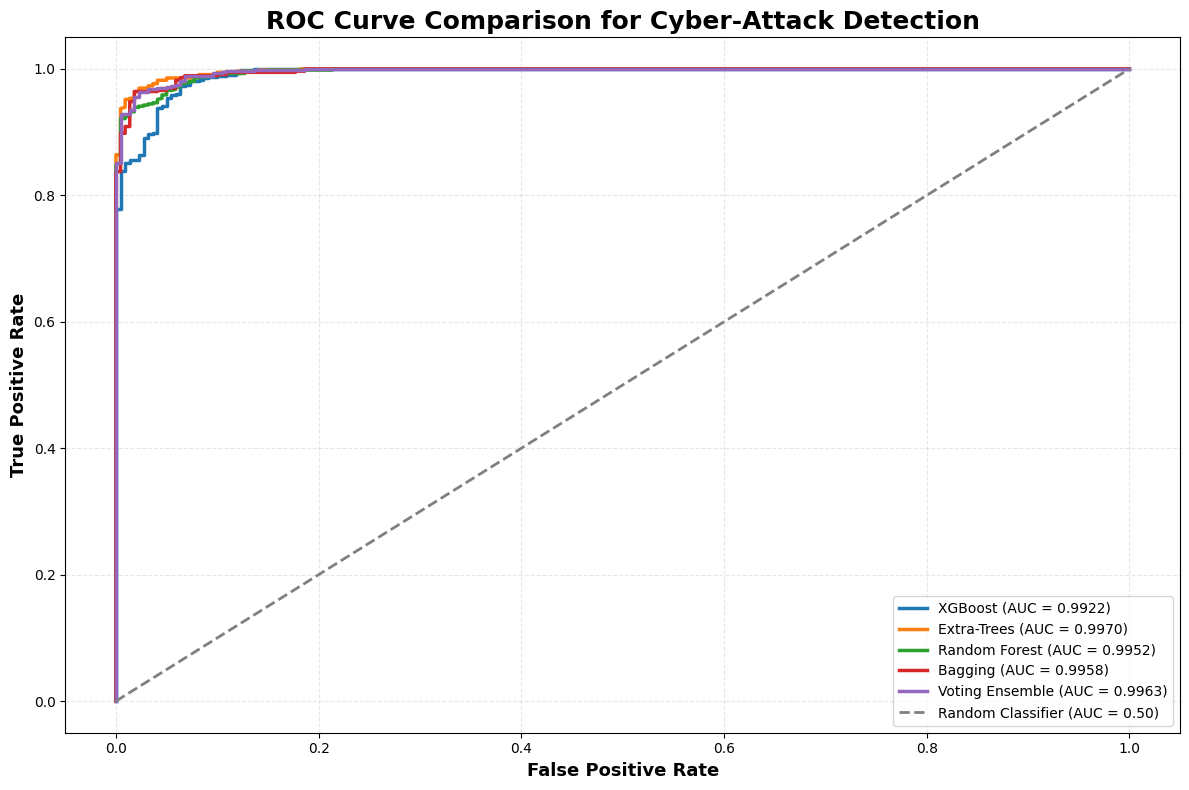


ROC-AUC RESULTS
          Model      AUC
    Extra-Trees 0.996989
Voting Ensemble 0.996266
        Bagging 0.995791
  Random Forest 0.995211
        XGBoost 0.992192


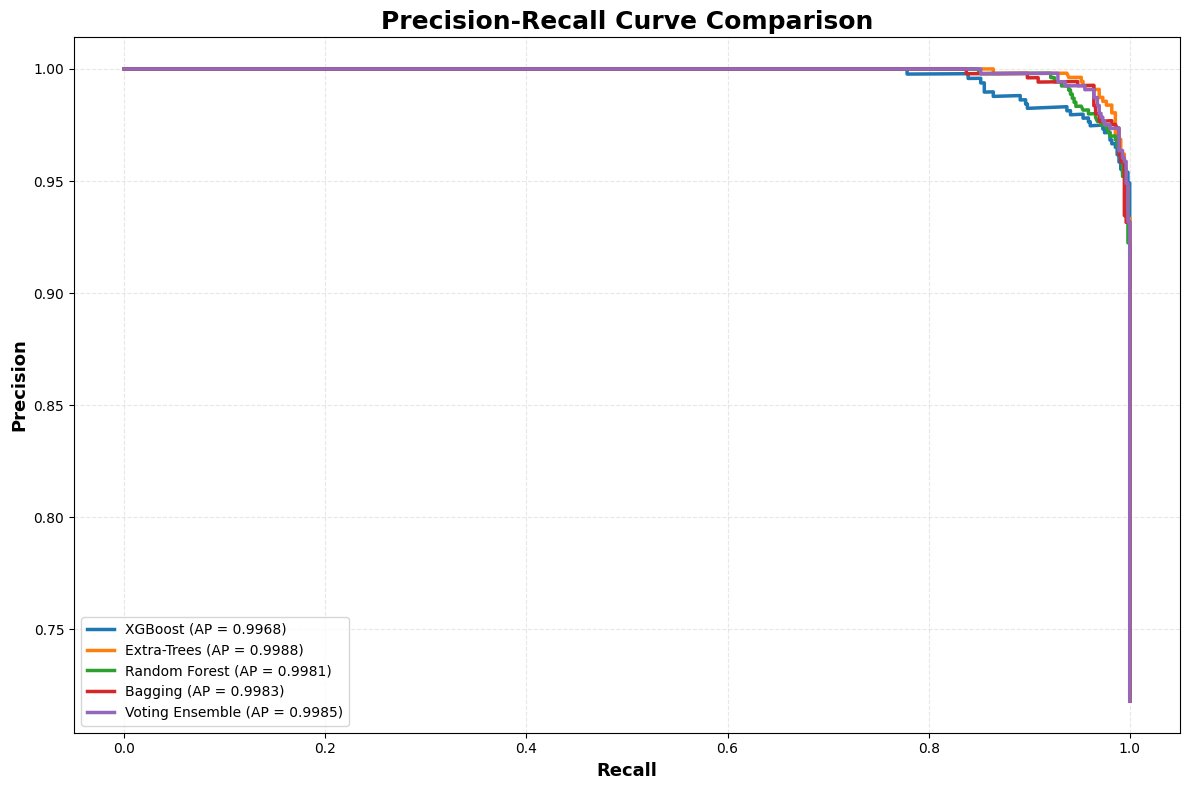


PRECISION-RECALL RESULTS
          Model  Average Precision
    Extra-Trees           0.998817
Voting Ensemble           0.998529
        Bagging           0.998340
  Random Forest           0.998111
        XGBoost           0.996808

10-FOLD STRATIFIED CROSS-VALIDATION
Running 10-fold CV: XGBoost
Running 10-fold CV: Extra-Trees
Running 10-fold CV: Random Forest
Running 10-fold CV: Bagging
Running 10-fold CV: Voting Ensemble


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



10-FOLD CV SUMMARY
                  mean   std    min    max
Model                                     
Extra-Trees      96.92  0.99  95.64  98.46
Voting Ensemble  96.77  1.11  95.38  98.21
Random Forest    96.44  1.31  94.36  97.69
XGBoost          96.44  1.28  94.10  97.95
Bagging          96.26  1.02  94.62  97.69


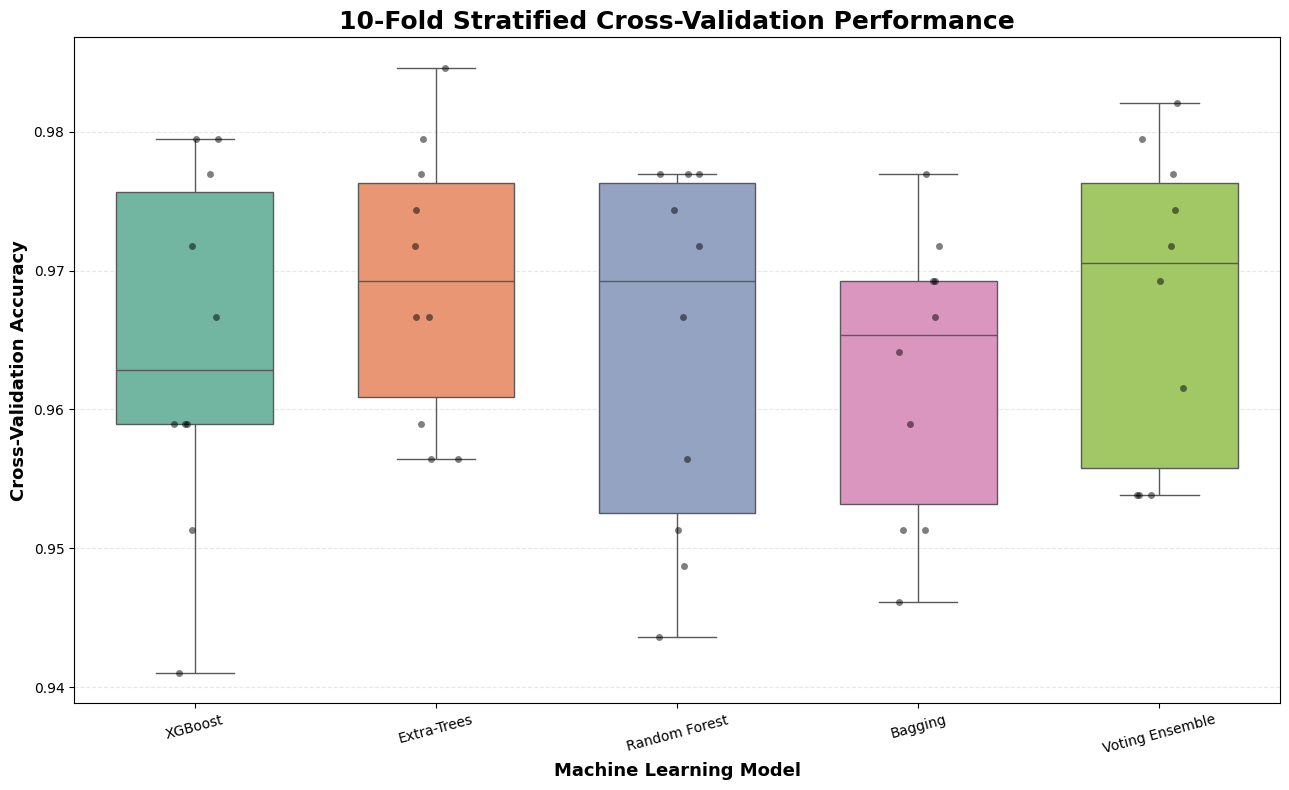

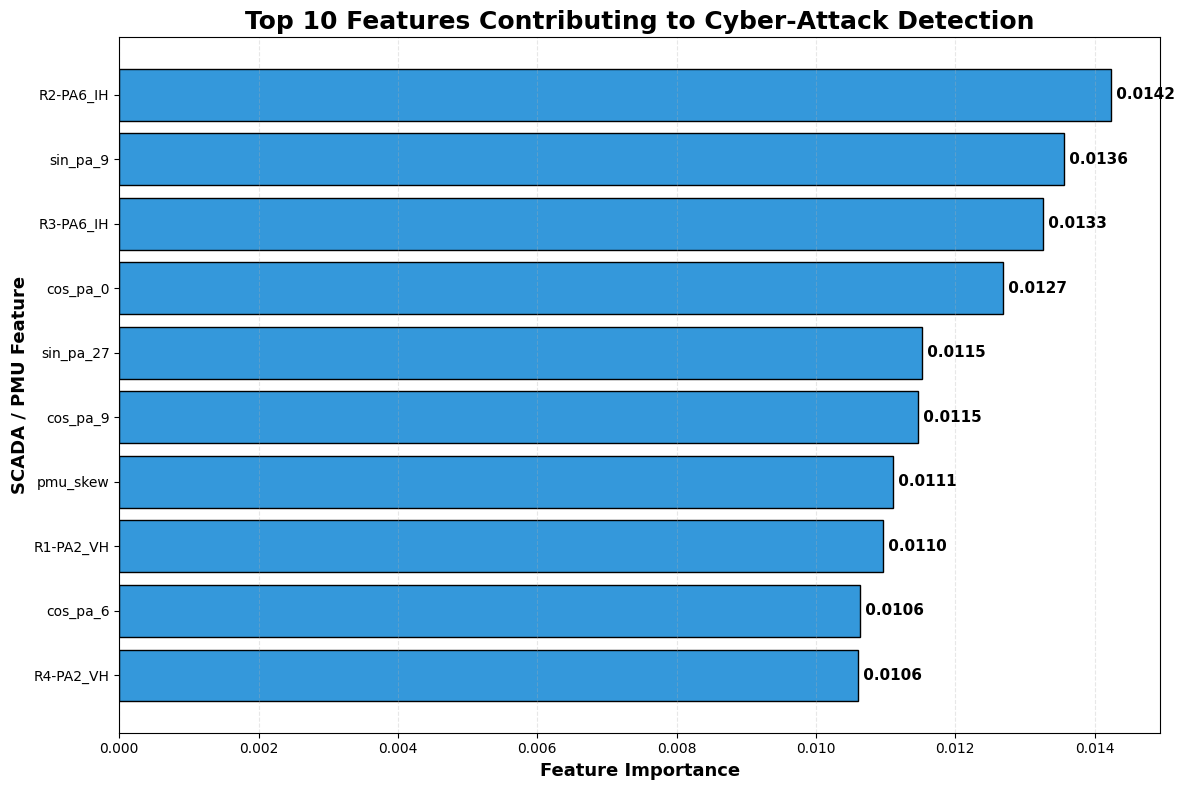


TOP 10 FEATURES
  Feature  Importance
R2-PA6_IH    0.014230
 sin_pa_9    0.013559
R3-PA6_IH    0.013251
 cos_pa_0    0.012678
sin_pa_27    0.011515
 cos_pa_9    0.011468
 pmu_skew    0.011111
R1-PA2_VH    0.010954
 cos_pa_6    0.010625
R4-PA2_VH    0.010604

COMPUTATIONAL COMPLEXITY & REAL-TIME PERFORMANCE
          Model Training Time (s) Prediction Time (s) Latency (ms/sample) Samples/sec Accuracy
        XGBoost            35.902               0.039              0.0502    19934.31   0.9654
    Extra-Trees             4.582               0.255              0.3264     3063.36   0.9705
  Random Forest            24.549               0.254              0.3261     3066.64   0.9654
        Bagging             6.692               1.426              1.8285      546.89   0.9654
Voting Ensemble            71.046               2.316              2.9697      336.74   0.9718


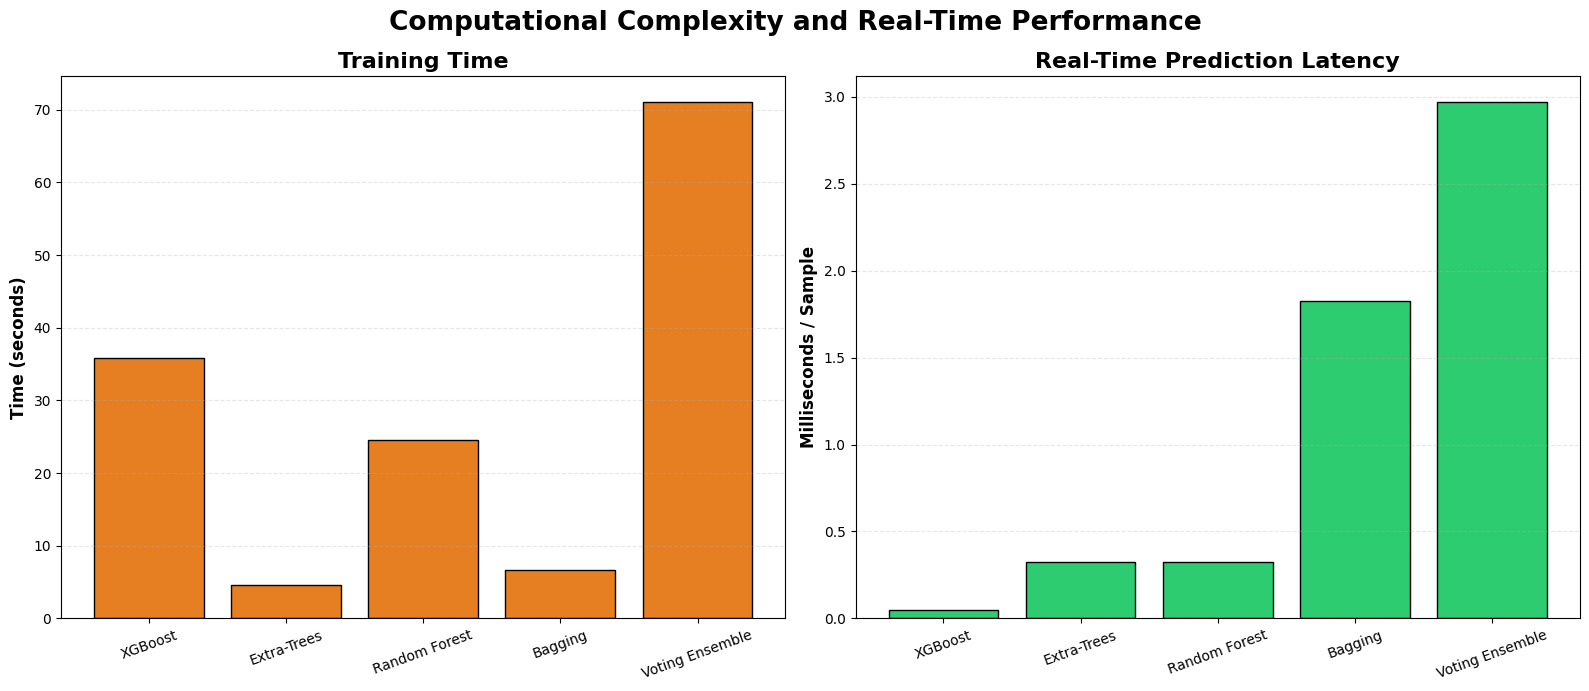

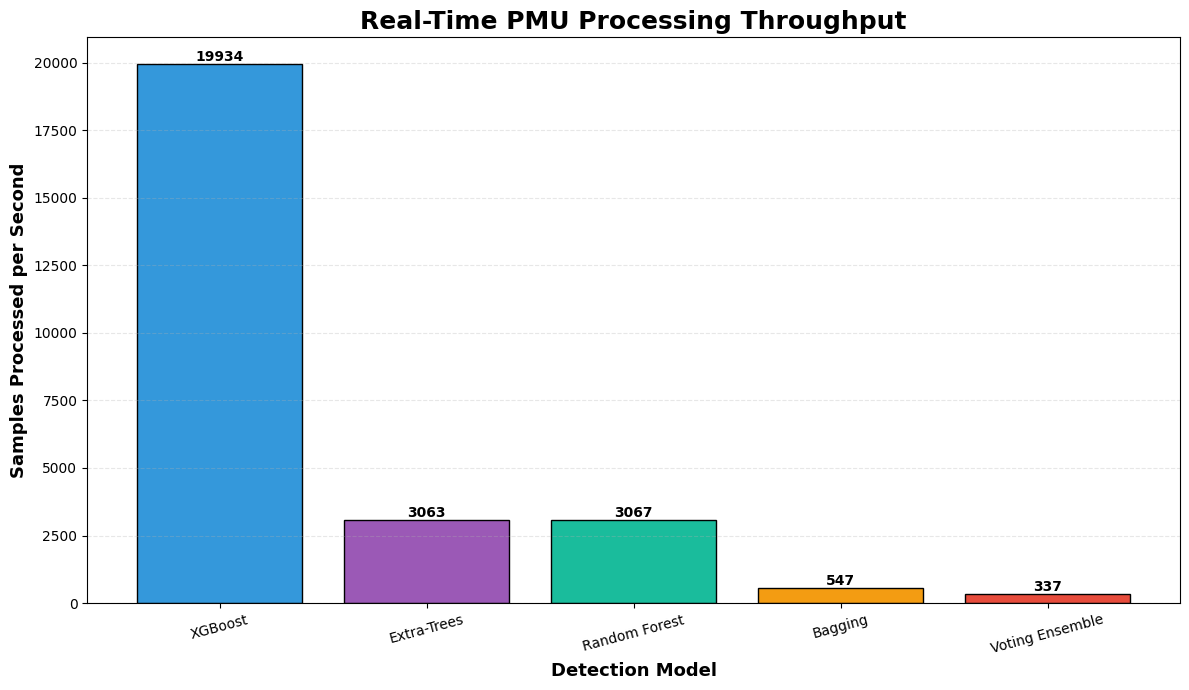


                 FINAL MODEL COMPARISON
          Model    AUC Average Precision CV Mean Accuracy CV Std Test Accuracy
        XGBoost 0.9922            0.9968           0.9644 0.0128        0.9654
    Extra-Trees 0.9970            0.9988           0.9692 0.0099        0.9705
  Random Forest 0.9952            0.9981           0.9644 0.0131        0.9654
        Bagging 0.9958            0.9983           0.9626 0.0102        0.9654
Voting Ensemble 0.9963            0.9985           0.9677 0.0111        0.9718


In [ ]:
# =============================================================
# 12. ADVANCED MODEL COMPARISON
# =============================================================
#
# 1. ROC Curves & AUC
# 2. Precision-Recall Curves
# 3. 10-Fold Cross-Validation Boxplot
# 4. Top-10 Feature Importance
# 5. Computational Complexity & Real-Time Performance
#
# Models:
#   - XGBoost
#   - Extra-Trees
#   - Random Forest
#   - Bagging
#   - Voting Ensemble
# =============================================================

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

from sklearn.model_selection import StratifiedKFold, cross_val_score

import seaborn as sns
from matplotlib.patches import Patch

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================
# MODEL DICTIONARY
# =============================================================

evaluation_models = {
    'XGBoost': xgb_model,
    'Extra-Trees': et_model,
    'Random Forest': rf_model,
    'Bagging': bagging_model,
    'Voting Ensemble': voting_ensemble
}


# =============================================================
# 1. ROC CURVES & AUC COMPARISON
# =============================================================

plt.figure(figsize=(12, 8))

roc_results = {}

for name, model in evaluation_models.items():

    # Probability of Cyber-Attack
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    roc_results[name] = auc_score

    plt.plot(
        fpr,
        tpr,
        linewidth=2.5,
        label=f'{name} (AUC = {auc_score:.4f})'
    )


# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    linewidth=2,
    label='Random Classifier (AUC = 0.50)'
)

plt.xlabel(
    'False Positive Rate',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'True Positive Rate',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'ROC Curve Comparison for Cyber-Attack Detection',
    fontsize=18,
    fontweight='bold'
)

plt.legend(
    loc='lower right',
    fontsize=10
)

plt.grid(
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'ROC_AUC_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# AUC SUMMARY
# =============================================================

auc_df = pd.DataFrame(
    list(roc_results.items()),
    columns=['Model', 'AUC']
).sort_values(
    'AUC',
    ascending=False
)

print("\nROC-AUC RESULTS")
print("=" * 60)
print(auc_df.to_string(index=False))


# =============================================================
# 2. PRECISION-RECALL CURVES
# =============================================================

plt.figure(figsize=(12, 8))

pr_results = {}

for name, model in evaluation_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        y_prob
    )

    ap_score = average_precision_score(
        y_test,
        y_prob
    )

    pr_results[name] = ap_score

    plt.plot(
        recall,
        precision,
        linewidth=2.5,
        label=f'{name} (AP = {ap_score:.4f})'
    )


plt.xlabel(
    'Recall',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'Precision',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'Precision-Recall Curve Comparison',
    fontsize=18,
    fontweight='bold'
)

plt.legend(
    loc='lower left',
    fontsize=10
)

plt.grid(
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'Precision_Recall_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# AP SUMMARY
# =============================================================

ap_df = pd.DataFrame(
    list(pr_results.items()),
    columns=['Model', 'Average Precision']
).sort_values(
    'Average Precision',
    ascending=False
)

print("\nPRECISION-RECALL RESULTS")
print("=" * 60)
print(ap_df.to_string(index=False))


# =============================================================
# 3. 10-FOLD CROSS-VALIDATION
# =============================================================

print("\n" + "=" * 80)
print("10-FOLD STRATIFIED CROSS-VALIDATION")
print("=" * 80)

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_results = []

# -------------------------------------------------------------
# IMPORTANT:
# Use X_eng instead of X_selected here.
#
# VarianceThreshold is fitted separately inside each fold
# to prevent feature-selection leakage.
# -------------------------------------------------------------

for name, model in evaluation_models.items():

    print(f"Running 10-fold CV: {name}")

    fold_scores = []

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_eng, y),
        start=1
    ):

        # Fold-specific data
        X_train_fold = X_eng.iloc[train_idx].copy()
        X_val_fold = X_eng.iloc[val_idx].copy()

        y_train_fold = y[train_idx]
        y_val_fold = y[val_idx]

        # -----------------------------------------
        # Fit variance selector ONLY on training fold
        # -----------------------------------------
        fold_selector = VarianceThreshold(
            threshold=0.001
        )

        X_train_fold = fold_selector.fit_transform(
            X_train_fold
        )

        X_val_fold = fold_selector.transform(
            X_val_fold
        )

        # -----------------------------------------
        # Clone model so each fold starts fresh
        # -----------------------------------------
        from sklearn.base import clone

        fold_model = clone(model)

        fold_model.fit(
            X_train_fold,
            y_train_fold
        )

        fold_prediction = fold_model.predict(
            X_val_fold
        )

        fold_accuracy = accuracy_score(
            y_val_fold,
            fold_prediction
        )

        fold_scores.append(
            fold_accuracy
        )

        cv_results.append({
            'Model': name,
            'Fold': fold,
            'Accuracy': fold_accuracy
        })


cv_df = pd.DataFrame(cv_results)


# =============================================================
# CV STATISTICS
# =============================================================

cv_summary = (
    cv_df
    .groupby('Model')['Accuracy']
    .agg(['mean', 'std', 'min', 'max'])
    .sort_values('mean', ascending=False)
)

print("\n10-FOLD CV SUMMARY")
print("=" * 80)

print(
    (cv_summary * 100).round(2).to_string()
)


# =============================================================
# CV BOXPLOT
# =============================================================

plt.figure(figsize=(13, 8))

sns.boxplot(
    data=cv_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='Set2',
    legend=False,
    width=0.65
)

sns.stripplot(
    data=cv_df,
    x='Model',
    y='Accuracy',
    color='black',
    alpha=0.5,
    size=5
)

plt.ylabel(
    'Cross-Validation Accuracy',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel(
    'Machine Learning Model',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    '10-Fold Stratified Cross-Validation Performance',
    fontsize=18,
    fontweight='bold'
)

plt.xticks(
    rotation=15
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    '10Fold_CrossValidation_Boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# 4. TOP-10 FEATURE IMPORTANCE
# =============================================================

# Extra-Trees provides feature_importances_
# Voting Ensemble itself does not directly provide one,
# therefore Extra-Trees is used as the feature-importance
# representative of the tree-based feature space.

selected_feature_names = X_eng.columns[
    selector.get_support()
]

feature_importance = et_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': selected_feature_names,
    'Importance': feature_importance
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        'Importance',
        ascending=False
    )
)

top10_features = (
    feature_importance_df
    .head(10)
    .sort_values(
        'Importance',
        ascending=True
    )
)


# =============================================================
# TOP-10 FEATURE PLOT
# =============================================================

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top10_features['Feature'],
    top10_features['Importance'],
    color='#3498db',
    edgecolor='black',
    linewidth=1
)

for bar, value in zip(
    bars,
    top10_features['Importance']
):

    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f' {value:.4f}',
        va='center',
        fontsize=11,
        fontweight='bold'
    )


plt.xlabel(
    'Feature Importance',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'SCADA / PMU Feature',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'Top 10 Features Contributing to Cyber-Attack Detection',
    fontsize=18,
    fontweight='bold'
)

plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'Top10_SCADA_Feature_Importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# PRINT TOP FEATURES
# =============================================================

print("\nTOP 10 FEATURES")
print("=" * 60)

print(
    feature_importance_df.head(10).to_string(
        index=False
    )
)


# =============================================================
# 5. COMPUTATIONAL COMPLEXITY & REAL-TIME PERFORMANCE
# =============================================================

print("\n" + "=" * 80)
print("COMPUTATIONAL COMPLEXITY & REAL-TIME PERFORMANCE")
print("=" * 80)

performance_results = []


for name, model in evaluation_models.items():

    # ---------------------------------------------------------
    # Training time
    # ---------------------------------------------------------

    start_train = time.perf_counter()

    model.fit(
        X_train,
        y_train
    )

    end_train = time.perf_counter()

    training_time = (
        end_train - start_train
    )


    # ---------------------------------------------------------
    # Prediction time
    # ---------------------------------------------------------

    start_predict = time.perf_counter()

    predictions = model.predict(
        X_test
    )

    end_predict = time.perf_counter()

    prediction_time = (
        end_predict - start_predict
    )


    # ---------------------------------------------------------
    # Per-sample prediction latency
    # ---------------------------------------------------------

    n_test_samples = len(X_test)

    latency_ms = (
        prediction_time /
        n_test_samples
    ) * 1000


    # ---------------------------------------------------------
    # Samples processed per second
    # ---------------------------------------------------------

    samples_per_second = (
        n_test_samples /
        prediction_time
    )


    # ---------------------------------------------------------
    # Model accuracy
    # ---------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        predictions
    )


    performance_results.append({

        'Model': name,

        'Training Time (s)':
            training_time,

        'Prediction Time (s)':
            prediction_time,

        'Latency (ms/sample)':
            latency_ms,

        'Samples/sec':
            samples_per_second,

        'Accuracy':
            accuracy
    })


performance_df = pd.DataFrame(
    performance_results
)


# =============================================================
# PERFORMANCE TABLE
# =============================================================

print(
    performance_df.to_string(
        index=False,
        formatters={
            'Training Time (s)': '{:.3f}'.format,
            'Prediction Time (s)': '{:.3f}'.format,
            'Latency (ms/sample)': '{:.4f}'.format,
            'Samples/sec': '{:.2f}'.format,
            'Accuracy': '{:.4f}'.format
        }
    )
)


# =============================================================
# COMPUTATIONAL TIME PLOT
# =============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)


# -------------------------------------------------------------
# Training time
# -------------------------------------------------------------

axes[0].bar(
    performance_df['Model'],
    performance_df['Training Time (s)'],
    color='#e67e22',
    edgecolor='black'
)

axes[0].set_title(
    'Training Time',
    fontsize=16,
    fontweight='bold'
)

axes[0].set_ylabel(
    'Time (seconds)',
    fontsize=12,
    fontweight='bold'
)

axes[0].tick_params(
    axis='x',
    rotation=20
)

axes[0].grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)


# -------------------------------------------------------------
# Prediction latency
# -------------------------------------------------------------

axes[1].bar(
    performance_df['Model'],
    performance_df['Latency (ms/sample)'],
    color='#2ecc71',
    edgecolor='black'
)

axes[1].set_title(
    'Real-Time Prediction Latency',
    fontsize=16,
    fontweight='bold'
)

axes[1].set_ylabel(
    'Milliseconds / Sample',
    fontsize=12,
    fontweight='bold'
)

axes[1].tick_params(
    axis='x',
    rotation=20
)

axes[1].grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)


plt.suptitle(
    'Computational Complexity and Real-Time Performance',
    fontsize=19,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    'Computational_RealTime_Performance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# REAL-TIME THROUGHPUT PLOT
# =============================================================

plt.figure(figsize=(12, 7))

bars = plt.bar(
    performance_df['Model'],
    performance_df['Samples/sec'],
    color=[
        '#3498db',
        '#9b59b6',
        '#1abc9c',
        '#f39c12',
        '#e74c3c'
    ],
    edgecolor='black'
)

for bar, value in zip(
    bars,
    performance_df['Samples/sec']
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.0f}',
        ha='center',
        va='bottom',
        fontweight='bold'
    )

plt.title(
    'Real-Time PMU Processing Throughput',
    fontsize=18,
    fontweight='bold'
)

plt.ylabel(
    'Samples Processed per Second',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel(
    'Detection Model',
    fontsize=13,
    fontweight='bold'
)

plt.xticks(
    rotation=15
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'RealTime_Throughput.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# FINAL COMPARISON TABLE
# =============================================================

final_comparison = pd.DataFrame({
    'Model': list(evaluation_models.keys()),
    'AUC': [
        roc_results[m]
        for m in evaluation_models.keys()
    ],
    'Average Precision': [
        pr_results[m]
        for m in evaluation_models.keys()
    ],
    'CV Mean Accuracy': [
        cv_summary.loc[m, 'mean']
        for m in evaluation_models.keys()
    ],
    'CV Std': [
        cv_summary.loc[m, 'std']
        for m in evaluation_models.keys()
    ],
    'Test Accuracy': [
        accuracy_score(
            y_test,
            evaluation_models[m].predict(X_test)
        )
        for m in evaluation_models.keys()
    ]
})


print("\n" + "=" * 100)
print("                 FINAL MODEL COMPARISON")
print("=" * 100)

print(
    final_comparison.to_string(
        index=False,
        formatters={
            'AUC': '{:.4f}'.format,
            'Average Precision': '{:.4f}'.format,
            'CV Mean Accuracy': '{:.4f}'.format,
            'CV Std': '{:.4f}'.format,
            'Test Accuracy': '{:.4f}'.format
        }
    )
)

print("=" * 100)

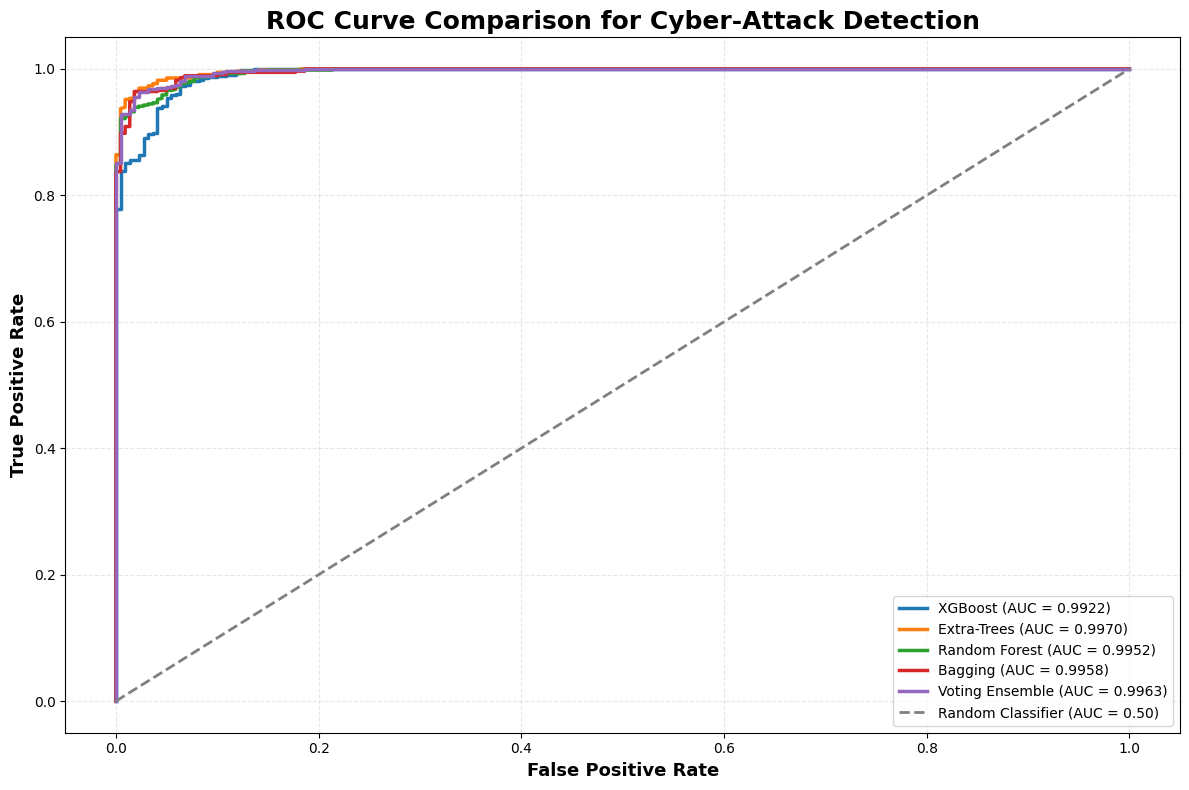


ROC-AUC RESULTS
          Model      AUC
    Extra-Trees 0.996989
Voting Ensemble 0.996266
        Bagging 0.995791
  Random Forest 0.995211
        XGBoost 0.992192


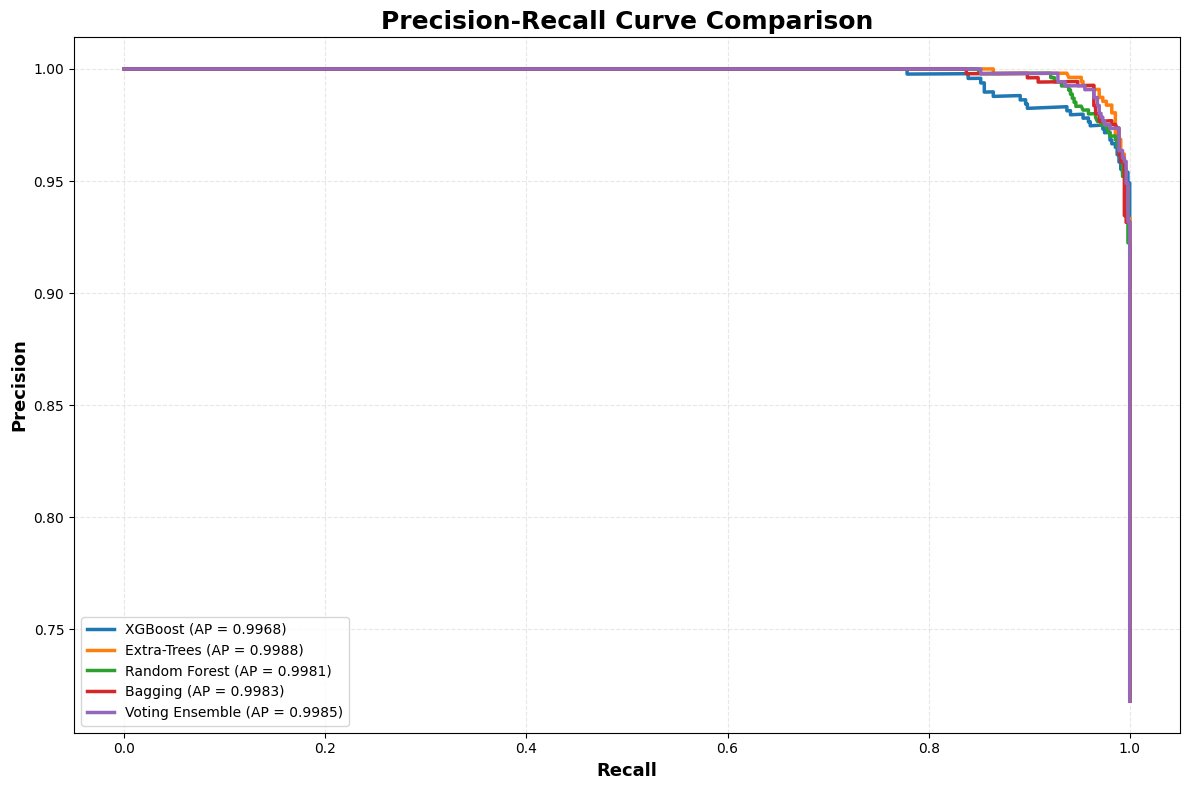


PRECISION-RECALL RESULTS
          Model  Average Precision
    Extra-Trees           0.998817
Voting Ensemble           0.998529
        Bagging           0.998340
  Random Forest           0.998111
        XGBoost           0.996808

10-FOLD STRATIFIED CROSS-VALIDATION
Running 10-fold CV: XGBoost
Running 10-fold CV: Extra-Trees
Running 10-fold CV: Random Forest
Running 10-fold CV: Bagging
Running 10-fold CV: Voting Ensemble


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



10-FOLD CV SUMMARY
                  mean   std    min    max
Model                                     
Extra-Trees      96.92  0.99  95.64  98.46
Voting Ensemble  96.77  1.11  95.38  98.21
Random Forest    96.44  1.31  94.36  97.69
XGBoost          96.44  1.28  94.10  97.95
Bagging          96.26  1.02  94.62  97.69


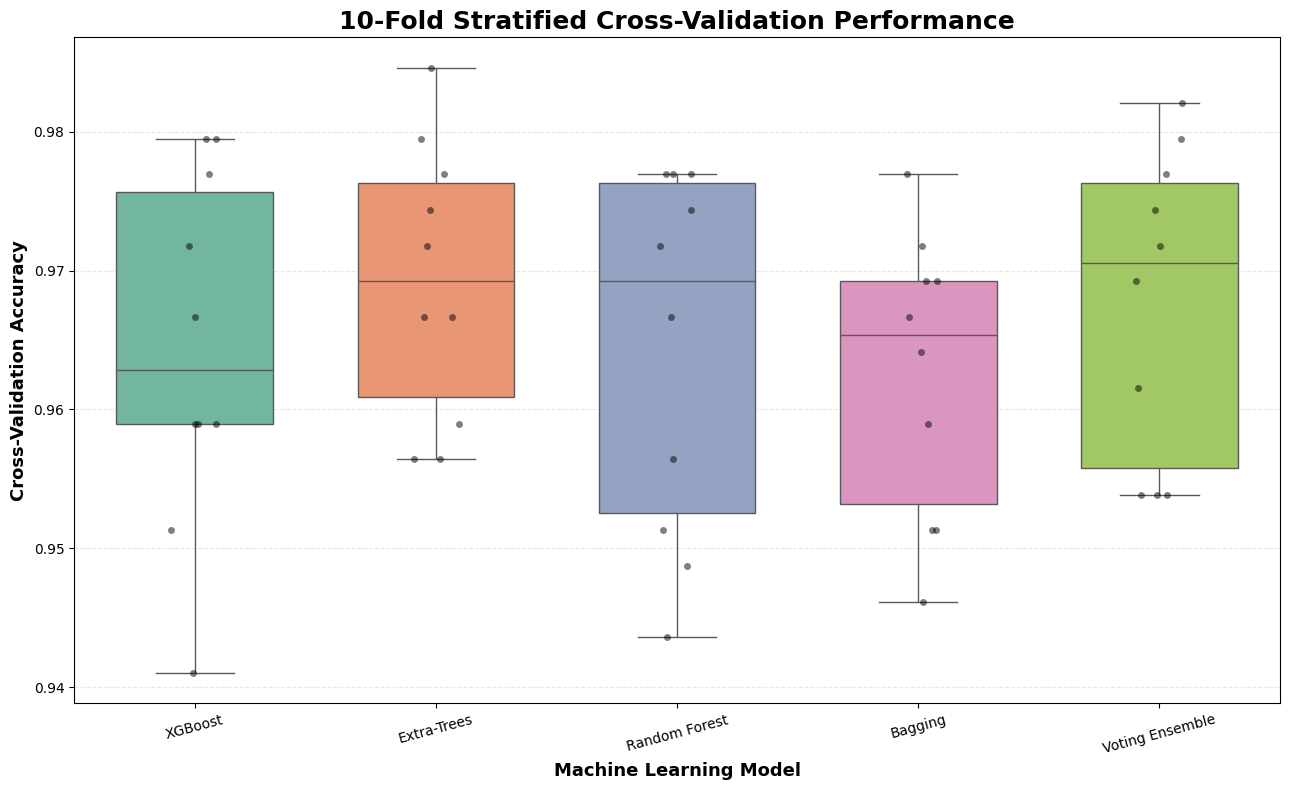

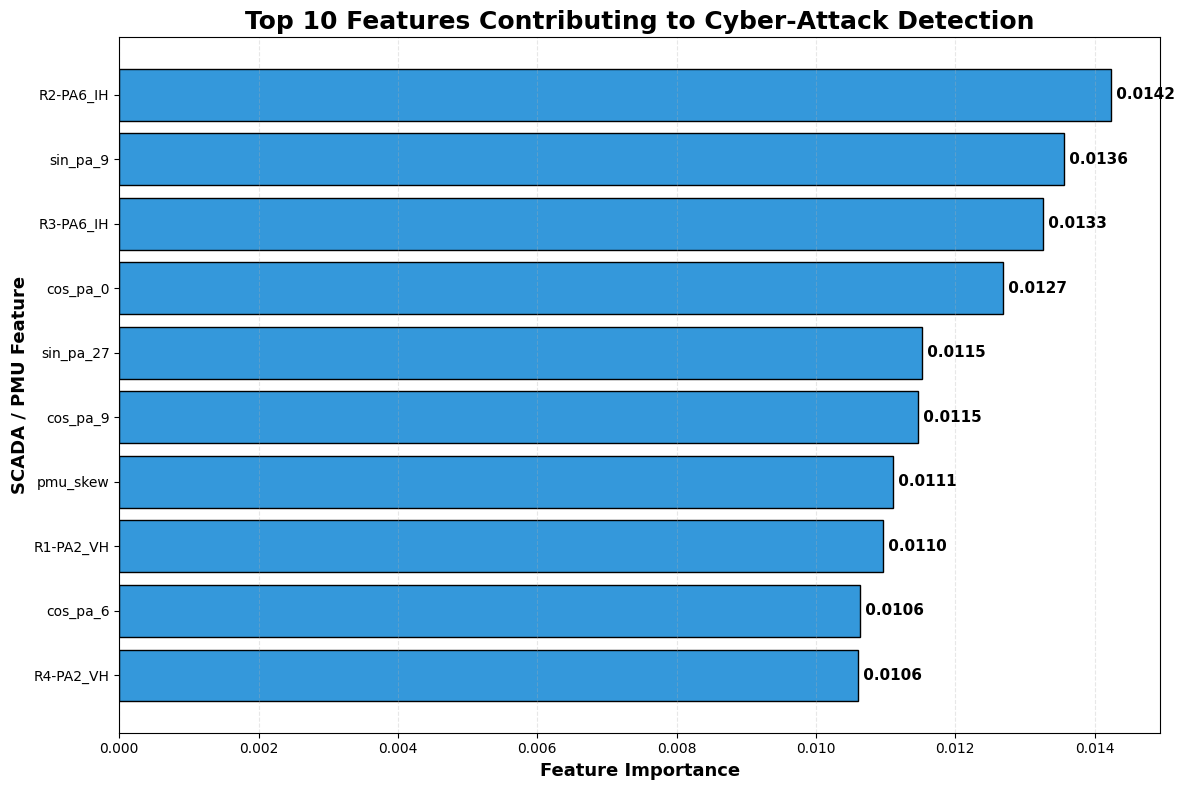


TOP 10 FEATURES
  Feature  Importance
R2-PA6_IH    0.014230
 sin_pa_9    0.013559
R3-PA6_IH    0.013251
 cos_pa_0    0.012678
sin_pa_27    0.011515
 cos_pa_9    0.011468
 pmu_skew    0.011111
R1-PA2_VH    0.010954
 cos_pa_6    0.010625
R4-PA2_VH    0.010604

COMPUTATIONAL COMPLEXITY & REAL-TIME PERFORMANCE
          Model Training Time (s) Prediction Time (s) Latency (ms/sample) Samples/sec Accuracy
        XGBoost            35.427               0.044              0.0559    17900.70   0.9654
    Extra-Trees             5.247               0.279              0.3580     2793.66   0.9705
  Random Forest            24.578               0.256              0.3276     3052.26   0.9654
        Bagging             7.163               1.370              1.7560      569.47   0.9654
Voting Ensemble            70.728               2.577              3.3043      302.64   0.9718


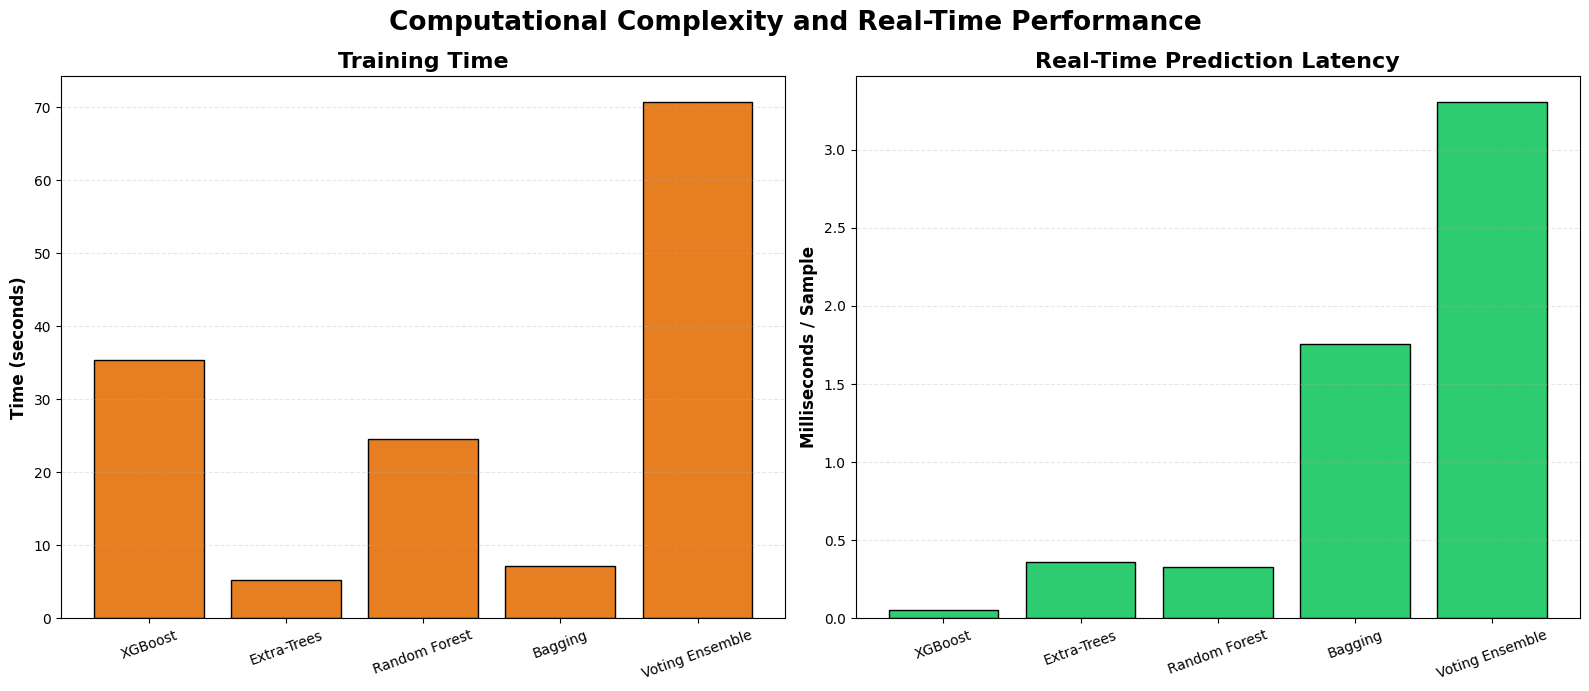

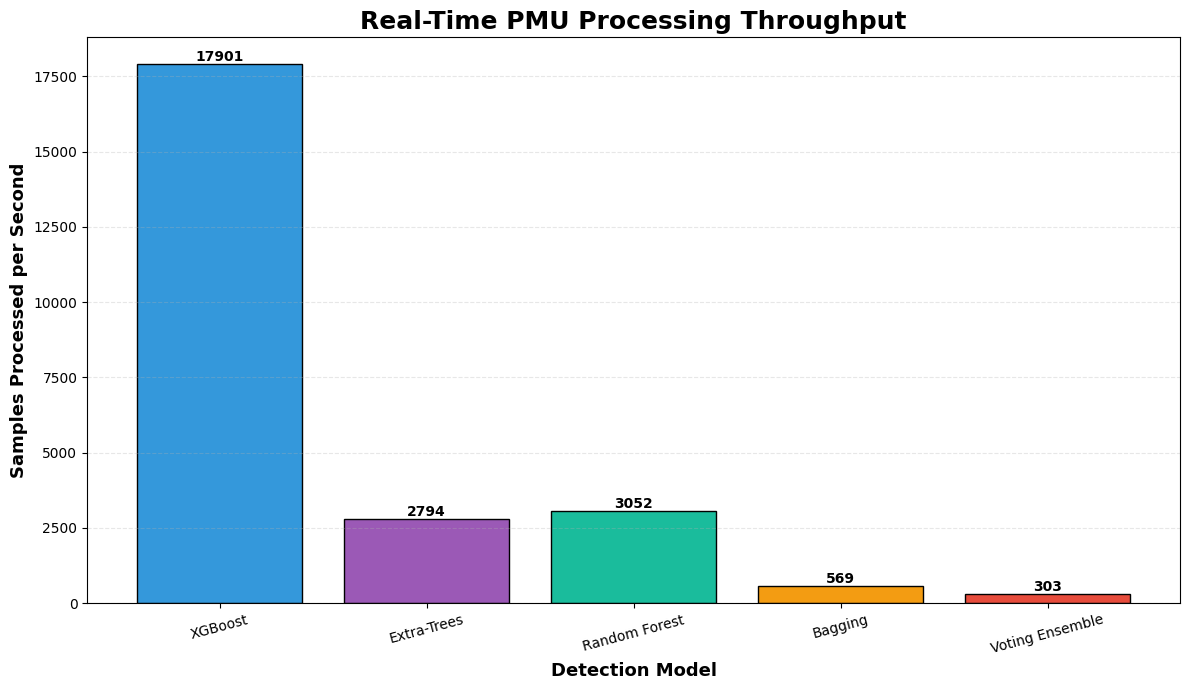


                 FINAL MODEL COMPARISON
          Model    AUC Average Precision CV Mean Accuracy CV Std Test Accuracy
        XGBoost 0.9922            0.9968           0.9644 0.0128        0.9654
    Extra-Trees 0.9970            0.9988           0.9692 0.0099        0.9705
  Random Forest 0.9952            0.9981           0.9644 0.0131        0.9654
        Bagging 0.9958            0.9983           0.9626 0.0102        0.9654
Voting Ensemble 0.9963            0.9985           0.9677 0.0111        0.9718


In [ ]:
# =============================================================
# 12. ADVANCED MODEL COMPARISON
# =============================================================
#
# 1. ROC Curves & AUC
# 2. Precision-Recall Curves
# 3. 10-Fold Cross-Validation Boxplot
# 4. Top-10 Feature Importance
# 5. Computational Complexity & Real-Time Performance
#
# Models:
#   - XGBoost
#   - Extra-Trees
#   - Random Forest
#   - Bagging
#   - Voting Ensemble
# =============================================================

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

from sklearn.model_selection import StratifiedKFold, cross_val_score

import seaborn as sns
from matplotlib.patches import Patch

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================
# MODEL DICTIONARY
# =============================================================

evaluation_models = {
    'XGBoost': xgb_model,
    'Extra-Trees': et_model,
    'Random Forest': rf_model,
    'Bagging': bagging_model,
    'Voting Ensemble': voting_ensemble
}


# =============================================================
# 1. ROC CURVES & AUC COMPARISON
# =============================================================

plt.figure(figsize=(12, 8))

roc_results = {}

for name, model in evaluation_models.items():

    # Probability of Cyber-Attack
    y_prob = model.predict_proba(X_test)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_prob
    )

    auc_score = roc_auc_score(
        y_test,
        y_prob
    )

    roc_results[name] = auc_score

    plt.plot(
        fpr,
        tpr,
        linewidth=2.5,
        label=f'{name} (AUC = {auc_score:.4f})'
    )


# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='gray',
    linewidth=2,
    label='Random Classifier (AUC = 0.50)'
)

plt.xlabel(
    'False Positive Rate',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'True Positive Rate',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'ROC Curve Comparison for Cyber-Attack Detection',
    fontsize=18,
    fontweight='bold'
)

plt.legend(
    loc='lower right',
    fontsize=10
)

plt.grid(
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'ROC_AUC_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# AUC SUMMARY
# =============================================================

auc_df = pd.DataFrame(
    list(roc_results.items()),
    columns=['Model', 'AUC']
).sort_values(
    'AUC',
    ascending=False
)

print("\nROC-AUC RESULTS")
print("=" * 60)
print(auc_df.to_string(index=False))


# =============================================================
# 2. PRECISION-RECALL CURVES
# =============================================================

plt.figure(figsize=(12, 8))

pr_results = {}

for name, model in evaluation_models.items():

    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        y_prob
    )

    ap_score = average_precision_score(
        y_test,
        y_prob
    )

    pr_results[name] = ap_score

    plt.plot(
        recall,
        precision,
        linewidth=2.5,
        label=f'{name} (AP = {ap_score:.4f})'
    )


plt.xlabel(
    'Recall',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'Precision',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'Precision-Recall Curve Comparison',
    fontsize=18,
    fontweight='bold'
)

plt.legend(
    loc='lower left',
    fontsize=10
)

plt.grid(
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'Precision_Recall_Comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# AP SUMMARY
# =============================================================

ap_df = pd.DataFrame(
    list(pr_results.items()),
    columns=['Model', 'Average Precision']
).sort_values(
    'Average Precision',
    ascending=False
)

print("\nPRECISION-RECALL RESULTS")
print("=" * 60)
print(ap_df.to_string(index=False))


# =============================================================
# 3. 10-FOLD CROSS-VALIDATION
# =============================================================

print("\n" + "=" * 80)
print("10-FOLD STRATIFIED CROSS-VALIDATION")
print("=" * 80)

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

cv_results = []

# -------------------------------------------------------------
# IMPORTANT:
# Use X_eng instead of X_selected here.
#
# VarianceThreshold is fitted separately inside each fold
# to prevent feature-selection leakage.
# -------------------------------------------------------------

for name, model in evaluation_models.items():

    print(f"Running 10-fold CV: {name}")

    fold_scores = []

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_eng, y),
        start=1
    ):

        # Fold-specific data
        X_train_fold = X_eng.iloc[train_idx].copy()
        X_val_fold = X_eng.iloc[val_idx].copy()

        y_train_fold = y[train_idx]
        y_val_fold = y[val_idx]

        # -----------------------------------------
        # Fit variance selector ONLY on training fold
        # -----------------------------------------
        fold_selector = VarianceThreshold(
            threshold=0.001
        )

        X_train_fold = fold_selector.fit_transform(
            X_train_fold
        )

        X_val_fold = fold_selector.transform(
            X_val_fold
        )

        # -----------------------------------------
        # Clone model so each fold starts fresh
        # -----------------------------------------
        from sklearn.base import clone

        fold_model = clone(model)

        fold_model.fit(
            X_train_fold,
            y_train_fold
        )

        fold_prediction = fold_model.predict(
            X_val_fold
        )

        fold_accuracy = accuracy_score(
            y_val_fold,
            fold_prediction
        )

        fold_scores.append(
            fold_accuracy
        )

        cv_results.append({
            'Model': name,
            'Fold': fold,
            'Accuracy': fold_accuracy
        })


cv_df = pd.DataFrame(cv_results)


# =============================================================
# CV STATISTICS
# =============================================================

cv_summary = (
    cv_df
    .groupby('Model')['Accuracy']
    .agg(['mean', 'std', 'min', 'max'])
    .sort_values('mean', ascending=False)
)

print("\n10-FOLD CV SUMMARY")
print("=" * 80)

print(
    (cv_summary * 100).round(2).to_string()
)


# =============================================================
# CV BOXPLOT
# =============================================================

plt.figure(figsize=(13, 8))

sns.boxplot(
    data=cv_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='Set2',
    legend=False,
    width=0.65
)

sns.stripplot(
    data=cv_df,
    x='Model',
    y='Accuracy',
    color='black',
    alpha=0.5,
    size=5
)

plt.ylabel(
    'Cross-Validation Accuracy',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel(
    'Machine Learning Model',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    '10-Fold Stratified Cross-Validation Performance',
    fontsize=18,
    fontweight='bold'
)

plt.xticks(
    rotation=15
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    '10Fold_CrossValidation_Boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# 4. TOP-10 FEATURE IMPORTANCE
# =============================================================

# Extra-Trees provides feature_importances_
# Voting Ensemble itself does not directly provide one,
# therefore Extra-Trees is used as the feature-importance
# representative of the tree-based feature space.

selected_feature_names = X_eng.columns[
    selector.get_support()
]

feature_importance = et_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': selected_feature_names,
    'Importance': feature_importance
})

feature_importance_df = (
    feature_importance_df
    .sort_values(
        'Importance',
        ascending=False
    )
)

top10_features = (
    feature_importance_df
    .head(10)
    .sort_values(
        'Importance',
        ascending=True
    )
)


# =============================================================
# TOP-10 FEATURE PLOT
# =============================================================

plt.figure(figsize=(12, 8))

bars = plt.barh(
    top10_features['Feature'],
    top10_features['Importance'],
    color='#3498db',
    edgecolor='black',
    linewidth=1
)

for bar, value in zip(
    bars,
    top10_features['Importance']
):

    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        f' {value:.4f}',
        va='center',
        fontsize=11,
        fontweight='bold'
    )


plt.xlabel(
    'Feature Importance',
    fontsize=13,
    fontweight='bold'
)

plt.ylabel(
    'SCADA / PMU Feature',
    fontsize=13,
    fontweight='bold'
)

plt.title(
    'Top 10 Features Contributing to Cyber-Attack Detection',
    fontsize=18,
    fontweight='bold'
)

plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'Top10_SCADA_Feature_Importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# PRINT TOP FEATURES
# =============================================================

print("\nTOP 10 FEATURES")
print("=" * 60)

print(
    feature_importance_df.head(10).to_string(
        index=False
    )
)


# =============================================================
# 5. COMPUTATIONAL COMPLEXITY & REAL-TIME PERFORMANCE
# =============================================================

print("\n" + "=" * 80)
print("COMPUTATIONAL COMPLEXITY & REAL-TIME PERFORMANCE")
print("=" * 80)

performance_results = []


for name, model in evaluation_models.items():

    # ---------------------------------------------------------
    # Training time
    # ---------------------------------------------------------

    start_train = time.perf_counter()

    model.fit(
        X_train,
        y_train
    )

    end_train = time.perf_counter()

    training_time = (
        end_train - start_train
    )


    # ---------------------------------------------------------
    # Prediction time
    # ---------------------------------------------------------

    start_predict = time.perf_counter()

    predictions = model.predict(
        X_test
    )

    end_predict = time.perf_counter()

    prediction_time = (
        end_predict - start_predict
    )


    # ---------------------------------------------------------
    # Per-sample prediction latency
    # ---------------------------------------------------------

    n_test_samples = len(X_test)

    latency_ms = (
        prediction_time /
        n_test_samples
    ) * 1000


    # ---------------------------------------------------------
    # Samples processed per second
    # ---------------------------------------------------------

    samples_per_second = (
        n_test_samples /
        prediction_time
    )


    # ---------------------------------------------------------
    # Model accuracy
    # ---------------------------------------------------------

    accuracy = accuracy_score(
        y_test,
        predictions
    )


    performance_results.append({

        'Model': name,

        'Training Time (s)':
            training_time,

        'Prediction Time (s)':
            prediction_time,

        'Latency (ms/sample)':
            latency_ms,

        'Samples/sec':
            samples_per_second,

        'Accuracy':
            accuracy
    })


performance_df = pd.DataFrame(
    performance_results
)


# =============================================================
# PERFORMANCE TABLE
# =============================================================

print(
    performance_df.to_string(
        index=False,
        formatters={
            'Training Time (s)': '{:.3f}'.format,
            'Prediction Time (s)': '{:.3f}'.format,
            'Latency (ms/sample)': '{:.4f}'.format,
            'Samples/sec': '{:.2f}'.format,
            'Accuracy': '{:.4f}'.format
        }
    )
)


# =============================================================
# COMPUTATIONAL TIME PLOT
# =============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 7)
)


# -------------------------------------------------------------
# Training time
# -------------------------------------------------------------

axes[0].bar(
    performance_df['Model'],
    performance_df['Training Time (s)'],
    color='#e67e22',
    edgecolor='black'
)

axes[0].set_title(
    'Training Time',
    fontsize=16,
    fontweight='bold'
)

axes[0].set_ylabel(
    'Time (seconds)',
    fontsize=12,
    fontweight='bold'
)

axes[0].tick_params(
    axis='x',
    rotation=20
)

axes[0].grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)


# -------------------------------------------------------------
# Prediction latency
# -------------------------------------------------------------

axes[1].bar(
    performance_df['Model'],
    performance_df['Latency (ms/sample)'],
    color='#2ecc71',
    edgecolor='black'
)

axes[1].set_title(
    'Real-Time Prediction Latency',
    fontsize=16,
    fontweight='bold'
)

axes[1].set_ylabel(
    'Milliseconds / Sample',
    fontsize=12,
    fontweight='bold'
)

axes[1].tick_params(
    axis='x',
    rotation=20
)

axes[1].grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)


plt.suptitle(
    'Computational Complexity and Real-Time Performance',
    fontsize=19,
    fontweight='bold'
)

plt.tight_layout()

plt.savefig(
    'Computational_RealTime_Performance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# REAL-TIME THROUGHPUT PLOT
# =============================================================

plt.figure(figsize=(12, 7))

bars = plt.bar(
    performance_df['Model'],
    performance_df['Samples/sec'],
    color=[
        '#3498db',
        '#9b59b6',
        '#1abc9c',
        '#f39c12',
        '#e74c3c'
    ],
    edgecolor='black'
)

for bar, value in zip(
    bars,
    performance_df['Samples/sec']
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.0f}',
        ha='center',
        va='bottom',
        fontweight='bold'
    )

plt.title(
    'Real-Time PMU Processing Throughput',
    fontsize=18,
    fontweight='bold'
)

plt.ylabel(
    'Samples Processed per Second',
    fontsize=13,
    fontweight='bold'
)

plt.xlabel(
    'Detection Model',
    fontsize=13,
    fontweight='bold'
)

plt.xticks(
    rotation=15
)

plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    'RealTime_Throughput.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# =============================================================
# FINAL COMPARISON TABLE
# =============================================================

final_comparison = pd.DataFrame({
    'Model': list(evaluation_models.keys()),
    'AUC': [
        roc_results[m]
        for m in evaluation_models.keys()
    ],
    'Average Precision': [
        pr_results[m]
        for m in evaluation_models.keys()
    ],
    'CV Mean Accuracy': [
        cv_summary.loc[m, 'mean']
        for m in evaluation_models.keys()
    ],
    'CV Std': [
        cv_summary.loc[m, 'std']
        for m in evaluation_models.keys()
    ],
    'Test Accuracy': [
        accuracy_score(
            y_test,
            evaluation_models[m].predict(X_test)
        )
        for m in evaluation_models.keys()
    ]
})


print("\n" + "=" * 100)
print("                 FINAL MODEL COMPARISON")
print("=" * 100)

print(
    final_comparison.to_string(
        index=False,
        formatters={
            'AUC': '{:.4f}'.format,
            'Average Precision': '{:.4f}'.format,
            'CV Mean Accuracy': '{:.4f}'.format,
            'CV Std': '{:.4f}'.format,
            'Test Accuracy': '{:.4f}'.format
        }
    )
)

print("=" * 100)